## **Problem Statement**

- X Education wants to identify which website visitors are most likely to become paying customers.
- The goal is to predict lead conversion and help the sales team focus on high-potential leads.

### **1. Understanding the dataset**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [ ]:
df = pd.read_csv('Lead-Scoring-Assignment/Leads.csv')
df.head()

,Prospect ID,Lead Number,Lead Origin,Lead Source,Do Not Email,Do Not Call,Converted,TotalVisits,Total Time Spent on Website,Page Views Per Visit,...,Get updates on DM Content,Lead Profile,City,Asymmetrique Activity Index,Asymmetrique Profile Index,Asymmetrique Activity Score,Asymmetrique Profile Score,I agree to pay the amount through cheque,A free copy of Mastering The Interview,Last Notable Activity
0,7927b2df-8bba-4d29-b9a2-b6e0beafe620,660737,API,Olark Chat,No,No,0,0.0,0,0.0,...,No,Select,Select,02.Medium,02.Medium,15.0,15.0,No,No,Modified
1,2a272436-5132-4136-86fa-dcc88c88f482,660728,API,Organic Search,No,No,0,5.0,674,2.5,...,No,Select,Select,02.Medium,02.Medium,15.0,15.0,No,No,Email Opened
2,8cc8c611-a219-4f35-ad23-fdfd2656bd8a,660727,Landing Page Submission,Direct Traffic,No,No,1,2.0,1532,2.0,...,No,Potential Lead,Mumbai,02.Medium,01.High,14.0,20.0,No,Yes,Email Opened
3,0cc2df48-7cf4-4e39-9de9-19797f9b38cc,660719,Landing Page Submission,Direct Traffic,No,No,0,1.0,305,1.0,...,No,Select,Mumbai,02.Medium,01.High,13.0,17.0,No,No,Modified
4,3256f628-e534-4826-9d63-4a8b88782852,660681,Landing Page Submission,Google,No,No,1,2.0,1428,1.0,...,No,Select,Mumbai,02.Medium,01.High,15.0,18.0,No,No,Modified


In [3]:
df_original = df.copy()

In [4]:
df.shape

(9240, 37)

In [5]:
df.info(verbose=True)

<class 'pandas.DataFrame'>
RangeIndex: 9240 entries, 0 to 9239
Data columns (total 37 columns):
 #   Column                                         Non-Null Count  Dtype  
---  ------                                         --------------  -----  
 0   Prospect ID                                    9240 non-null   str    
 1   Lead Number                                    9240 non-null   int64  
 2   Lead Origin                                    9240 non-null   str    
 3   Lead Source                                    9204 non-null   str    
 4   Do Not Email                                   9240 non-null   str    
 5   Do Not Call                                    9240 non-null   str    
 6   Converted                                      9240 non-null   int64  
 7   TotalVisits                                    9103 non-null   float64
 8   Total Time Spent on Website                    9240 non-null   int64  
 9   Page Views Per Visit                           9103 non-null   

In [6]:
df.describe(include='all')

,Prospect ID,Lead Number,Lead Origin,Lead Source,Do Not Email,Do Not Call,Converted,TotalVisits,Total Time Spent on Website,Page Views Per Visit,...,Get updates on DM Content,Lead Profile,City,Asymmetrique Activity Index,Asymmetrique Profile Index,Asymmetrique Activity Score,Asymmetrique Profile Score,I agree to pay the amount through cheque,A free copy of Mastering The Interview,Last Notable Activity
count,9240,9240.000000,9240,9204,9240,9240,9240.000000,9103.000000,9240.000000,9103.000000,...,9240,6531,7820,5022,5022,5022.000000,5022.000000,9240,9240,9240
unique,9240,NaN,5,21,2,2,NaN,NaN,NaN,NaN,...,1,6,7,3,3,NaN,NaN,1,2,16
top,7927b2df-8bba-4d29-b9a2-b6e0beafe620,NaN,Landing Page Submission,Google,No,No,NaN,NaN,NaN,NaN,...,No,Select,Mumbai,02.Medium,02.Medium,NaN,NaN,No,No,Modified
freq,1,NaN,4886,2868,8506,9238,NaN,NaN,NaN,NaN,...,9240,4146,3222,3839,2788,NaN,NaN,9240,6352,3407
mean,NaN,617188.435606,NaN,NaN,NaN,NaN,0.385390,3.445238,487.698268,2.362820,...,NaN,NaN,NaN,NaN,NaN,14.306252,16.344883,NaN,NaN,NaN
std,NaN,23405.995698,NaN,NaN,NaN,NaN,0.486714,4.854853,548.021466,2.161418,...,NaN,NaN,NaN,NaN,NaN,1.386694,1.811395,NaN,NaN,NaN
min,NaN,579533.000000,NaN,NaN,NaN,NaN,0.000000,0.000000,0.000000,0.000000,...,NaN,NaN,NaN,NaN,NaN,7.000000,11.000000,NaN,NaN,NaN
25%,NaN,596484.500000,NaN,NaN,NaN,NaN,0.000000,1.000000,12.000000,1.000000,...,NaN,NaN,NaN,NaN,NaN,14.000000,15.000000,NaN,NaN,NaN
50%,NaN,615479.000000,NaN,NaN,NaN,NaN,0.000000,3.000000,248.000000,2.000000,...,NaN,NaN,NaN,NaN,NaN,14.000000,16.000000,NaN,NaN,NaN
75%,NaN,637387.250000,NaN,NaN,NaN,NaN,1.000000,5.000000,936.000000,3.000000,...,NaN,NaN,NaN,NaN,NaN,15.000000,18.000000,NaN,NaN,NaN


In [7]:
df['Converted'].value_counts(normalize=True) * 100

Converted
0    61.461039
1    38.538961
Name: proportion, dtype: float64

In [8]:
(df == "Select").sum().sum()

np.int64(13380)

In [9]:
df = df.replace("Select", np.nan)
# Treat "Select" as missing as specified in the assignment

In [10]:
(df == "Select").sum().sum()

np.int64(0)

### **2. Data Cleaning**

#####  Missing Value Treatment

In [11]:
df.isnull().sum()

Prospect ID                                         0
Lead Number                                         0
Lead Origin                                         0
Lead Source                                        36
Do Not Email                                        0
Do Not Call                                         0
Converted                                           0
TotalVisits                                       137
Total Time Spent on Website                         0
Page Views Per Visit                              137
Last Activity                                     103
Country                                          2461
Specialization                                   3380
How did you hear about X Education               7250
What is your current occupation                  2690
What matters most to you in choosing a course    2709
Search                                              0
Magazine                                            0
Newspaper Article           

In [12]:
missing_percent = (df.isna().mean() * 100).sort_values(ascending=False)
missing_percent

How did you hear about X Education               78.463203
Lead Profile                                     74.188312
Lead Quality                                     51.590909
Asymmetrique Profile Index                       45.649351
Asymmetrique Activity Index                      45.649351
Asymmetrique Activity Score                      45.649351
Asymmetrique Profile Score                       45.649351
City                                             39.707792
Specialization                                   36.580087
Tags                                             36.287879
What matters most to you in choosing a course    29.318182
What is your current occupation                  29.112554
Country                                          26.634199
Page Views Per Visit                              1.482684
TotalVisits                                       1.482684
Last Activity                                     1.114719
Lead Source                                       0.3896

##### Removing column 'How did you hear about X Education'
- The column has 78.46% missing values. Therefore, the column is being dropped from further analysis.

In [13]:
df.drop("How did you hear about X Education", axis=1, inplace=True)

In [14]:
df[['TotalVisits', 'Page Views Per Visit']].describe()

,TotalVisits,Page Views Per Visit
count,9103.000000,9103.000000
mean,3.445238,2.362820
std,4.854853,2.161418
min,0.000000,0.000000
25%,1.000000,1.000000
50%,3.000000,2.000000
75%,5.000000,3.000000
max,251.000000,55.000000


In [15]:
## Check leads where both visit-related metrics are missing
(df["TotalVisits"].isna() & df["Page Views Per Visit"].isna()).sum()

np.int64(137)

In [16]:
# Check whether missing values in TotalVisits and Page Views Per Visit occur in the same rows
(df["TotalVisits"].isna() == df["Page Views Per Visit"].isna()).all()

np.True_

In [17]:
df.loc[
    df["TotalVisits"].isna(),
    ["TotalVisits", "Page Views Per Visit", "Total Time Spent on Website"]
].describe()

,TotalVisits,Page Views Per Visit,Total Time Spent on Website
count,0.0,0.0,137.000000
mean,NaN,NaN,909.503650
std,NaN,NaN,580.354723
min,NaN,NaN,11.000000
25%,NaN,NaN,341.000000
50%,NaN,NaN,1010.000000
75%,NaN,NaN,1413.000000
max,NaN,NaN,2217.000000


#####  Imputing Missing Values Using Median
- The columns 'TotalVisits' and 'Page Views Per Visit' each contain **137 missing values**.

- These missing values occur in the **same 137 rows**. However, 'Total Time Spent on Website' is not missing for these rows. So, we will retain them and impute the missing 'TotalVisits' and 'Page Views Per Visit' values using the median.

In [18]:
df["TotalVisits"] = df["TotalVisits"].fillna(
    df["TotalVisits"].median()
)

df["Page Views Per Visit"] = df["Page Views Per Visit"].fillna(
    df["Page Views Per Visit"].median()
)

##### Replacing Missing Values with 'Unknown' for Categorical Columns
- Missing values are replaced with "Unknown" to retain all records while preserving the fact that the information was not provided.
This allows the model to treat missing information as a separate category during analysis.

In [19]:
categorical_missing_cols = [
    "Lead Quality",
    'Lead Source',
    "Last Activity",
    "Lead Profile",
    "City",
    "Specialization",
    "Tags",
    "What matters most to you in choosing a course",
    "What is your current occupation",
    "Country"
]

df[categorical_missing_cols] = df[categorical_missing_cols].fillna("Unknown")

In [20]:
df[['Asymmetrique Activity Index','Asymmetrique Profile Index',
    'Asymmetrique Activity Score','Asymmetrique Profile Score']].isnull().sum()

Asymmetrique Activity Index    4218
Asymmetrique Profile Index     4218
Asymmetrique Activity Score    4218
Asymmetrique Profile Score     4218
dtype: int64

In [21]:
# check correlation/relationship with target before dropping
df.groupby('Converted')[['Asymmetrique Activity Score','Asymmetrique Profile Score']].mean()

,Asymmetrique Activity Score,Asymmetrique Profile Score
Converted,,
0,14.123956,16.035003
1,14.603774,16.850629


In [22]:
# Cross-tab counts
print(pd.crosstab(df['Asymmetrique Activity Index'], df['Converted'], normalize='index') * 100)
print()
print(pd.crosstab(df['Asymmetrique Profile Index'], df['Converted'], normalize='index') * 100)

Converted                            0          1
Asymmetrique Activity Index                      
01.High                      70.158343  29.841657
02.Medium                    57.541026  42.458974
03.Low                       90.883978   9.116022

Converted                           0          1
Asymmetrique Profile Index                      
01.High                     52.564685  47.435315
02.Medium                   69.583931  30.416069
03.Low                      51.612903  48.387097


##### Handling Asymmetrique Columns
- The Asymmetrique Activity Score and Asymmetrique Profile Score columns are being dropped due to their high proportion of missing values (approximately 46% each). Their conversion rates also showed only a small difference between converted and non-converted leads.

In [23]:
#Dropped the two Score columns (weak separation by target)
df.drop(['Asymmetrique Activity Score', 'Asymmetrique Profile Score'], axis=1, inplace=True)

In [24]:
#Fill missing values in the two Index columns with 'Unknown' (they showed real separation)
df['Asymmetrique Activity Index'] = df['Asymmetrique Activity Index'].fillna('Unknown')
df['Asymmetrique Profile Index'] = df['Asymmetrique Profile Index'].fillna('Unknown')

In [25]:
df.isnull().sum().sum()

np.int64(0)

In [26]:
df.duplicated().sum()

np.int64(0)

In [27]:
df_clean = df.copy()

In [28]:
df.describe()

,Lead Number,Converted,TotalVisits,Total Time Spent on Website,Page Views Per Visit
count,9240.000000,9240.000000,9240.000000,9240.000000,9240.000000
mean,617188.435606,0.385390,3.438636,487.698268,2.357440
std,23405.995698,0.486714,4.819024,548.021466,2.145781
min,579533.000000,0.000000,0.000000,0.000000,0.000000
25%,596484.500000,0.000000,1.000000,12.000000,1.000000
50%,615479.000000,0.000000,3.000000,248.000000,2.000000
75%,637387.250000,1.000000,5.000000,936.000000,3.000000
max,660737.000000,1.000000,251.000000,2272.000000,55.000000


In [29]:
# Check the percentage of the most common category in each categorical column
for col in df.select_dtypes(include="object").columns:
    top_pct = df[col].value_counts(normalize=True, dropna=False).iloc[0] * 100
    print(f"{col}: {top_pct:.2f}%")

Prospect ID: 0.01%
Lead Origin: 52.88%
Lead Source: 31.04%
Do Not Email: 92.06%
Do Not Call: 99.98%
Last Activity: 37.20%
Country: 70.26%
Specialization: 36.58%
What is your current occupation: 60.61%
What matters most to you in choosing a course: 70.65%
Search: 99.85%
Magazine: 100.00%
Newspaper Article: 99.98%
X Education Forums: 99.99%
Newspaper: 99.99%
Digital Advertisement: 99.96%
Through Recommendations: 99.92%
Receive More Updates About Our Courses: 100.00%
Tags: 36.29%
Lead Quality: 51.59%
Update me on Supply Chain Content: 100.00%
Get updates on DM Content: 100.00%
Lead Profile: 74.19%
City: 39.71%
Asymmetrique Activity Index: 45.65%
Asymmetrique Profile Index: 45.65%
I agree to pay the amount through cheque: 100.00%
A free copy of Mastering The Interview: 68.74%
Last Notable Activity: 36.87%


#### Removing low-variation variables

Several categorical variables have almost all observations in a single category, providing very little variation for the model. These constant or near-constant variables are removed to reduce redundancy and improve model efficiency.

In [30]:
high_dominance_cols = []

for col in df.columns:
    if col in ["Converted", "Prospect ID"]:
        continue

    top_pct = df[col].value_counts(normalize=True, dropna=False).iloc[0] * 100

    if top_pct > 98:
        high_dominance_cols.append(col)

print("Columns to remove:")
print(high_dominance_cols)

Columns to remove:
['Do Not Call', 'Search', 'Magazine', 'Newspaper Article', 'X Education Forums', 'Newspaper', 'Digital Advertisement', 'Through Recommendations', 'Receive More Updates About Our Courses', 'Update me on Supply Chain Content', 'Get updates on DM Content', 'I agree to pay the amount through cheque']


In [31]:
df = df.drop(columns=high_dominance_cols)


In [32]:
# removing identifiers that are not useful for modeling
df.drop(["Prospect ID", "Lead Number"], axis=1, inplace=True)

In [33]:
df.shape

(9240, 20)

In [34]:
df.dtypes

Lead Origin                                          str
Lead Source                                          str
Do Not Email                                         str
Converted                                          int64
TotalVisits                                      float64
Total Time Spent on Website                        int64
Page Views Per Visit                             float64
Last Activity                                        str
Country                                              str
Specialization                                       str
What is your current occupation                      str
What matters most to you in choosing a course        str
Tags                                                 str
Lead Quality                                         str
Lead Profile                                         str
City                                                 str
Asymmetrique Activity Index                          str
Asymmetrique Profile Index     

In [35]:
#Check invalid/inconsistent values
for col in df.select_dtypes(include="object").columns:
    print(col, df[col].unique())

Lead Origin <StringArray>
[                    'API', 'Landing Page Submission',
           'Lead Add Form',             'Lead Import',
          'Quick Add Form']
Length: 5, dtype: str
Lead Source <StringArray>
[       'Olark Chat',    'Organic Search',    'Direct Traffic',
            'Google',    'Referral Sites',  'Welingak Website',
         'Reference',            'google',          'Facebook',
           'Unknown',              'blog', 'Pay per Click Ads',
              'bing',      'Social Media',           'WeLearn',
        'Click2call',         'Live Chat',  'welearnblog_Home',
    'youtubechannel',           'testone',     'Press_Release',
            'NC_EDM']
Length: 22, dtype: str
Do Not Email <StringArray>
['No', 'Yes']
Length: 2, dtype: str
Last Activity <StringArray>
[     'Page Visited on Website',                 'Email Opened',
                  'Unreachable',            'Converted to Lead',
      'Olark Chat Conversation',                'Email Bounced',
         

In [36]:
# Checked categorical values for inconsistencies, standardized capitalization and spacing where required.
df["Lead Source"] = df["Lead Source"].replace({"google": "Google"})

df["Country"] = df["Country"].replace({"unknown": "Unknown"})

df["Tags"] = df["Tags"].str.replace(r"\s+", " ", regex=True)

In [37]:
# Check outliers in numerical predictor variables
num_cols = df.select_dtypes(include=["int64", "float64"]).columns.drop("Converted")

for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    outliers = ((df[col] < lower) | (df[col] > upper)).sum()
    
    print(f"{col}: {outliers} outliers")

TotalVisits: 267 outliers
Total Time Spent on Website: 0 outliers
Page Views Per Visit: 360 outliers


- Outliers were identified using the IQR method. 
- Potential outliers were retained because they may represent genuine lead behaviour.

#### 2. EDA (Exploratory Data Analysis)

In [38]:
# Check the distribution of the target variable
print(df["Converted"].value_counts())
print(df["Converted"].value_counts(normalize=True) * 100)

Converted
0    5679
1    3561
Name: count, dtype: int64
Converted
0    61.461039
1    38.538961
Name: proportion, dtype: float64


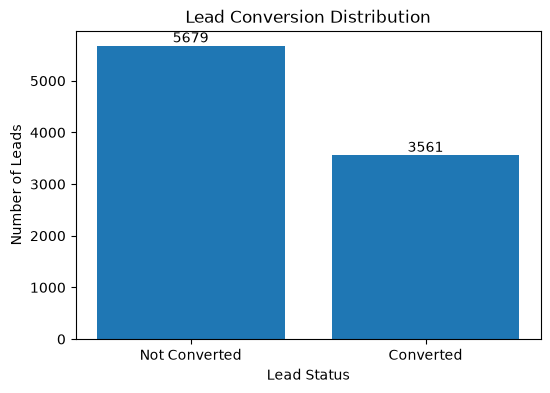

In [39]:
import matplotlib.pyplot as plt

conversion_counts = df['Converted'].value_counts().sort_index()

labels = ['Not Converted', 'Converted']
values = conversion_counts.values

plt.figure(figsize=(6, 4))
bars = plt.bar(labels, values)

plt.title('Lead Conversion Distribution')
plt.xlabel('Lead Status')
plt.ylabel('Number of Leads')

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        str(value),
        ha='center',
        va='bottom'
    )

plt.show()

##### 1. Univariate analysis

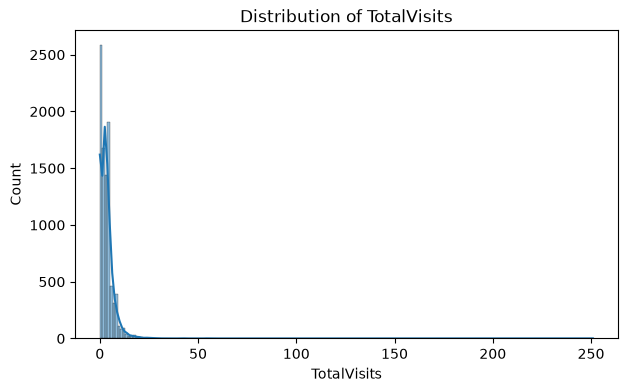

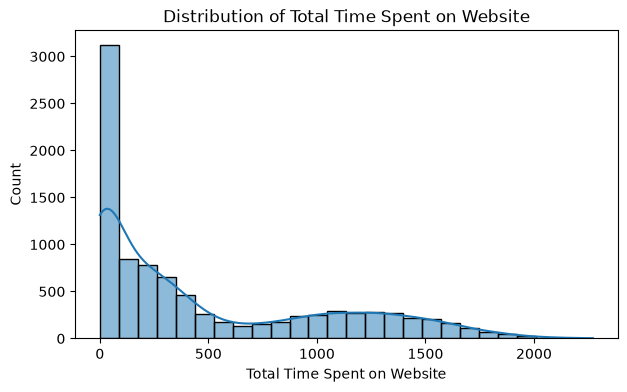

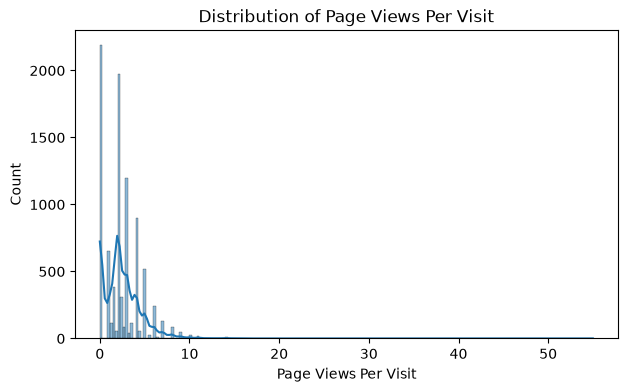

In [40]:
import matplotlib.pyplot as plt
import seaborn as sns

num_cols = ["TotalVisits", "Total Time Spent on Website", "Page Views Per Visit"]

for col in num_cols:
    plt.figure(figsize=(7, 4))
    sns.histplot(df[col], kde=True)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.show()

- All numerical variables are right-skewed, with a small number of leads having relatively high values.

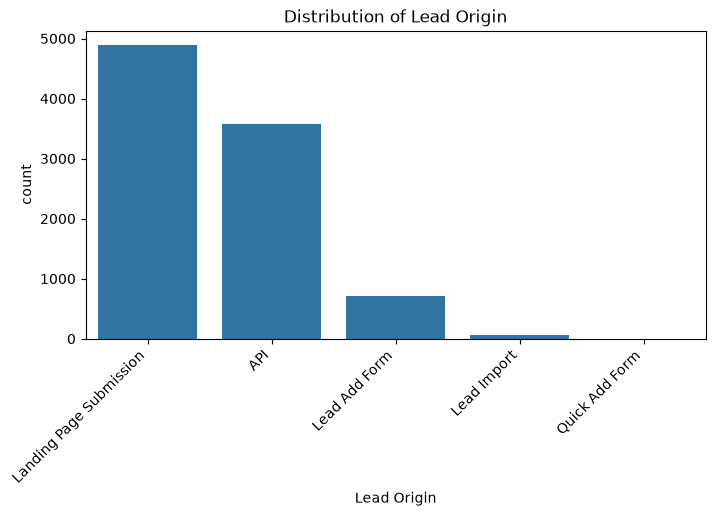

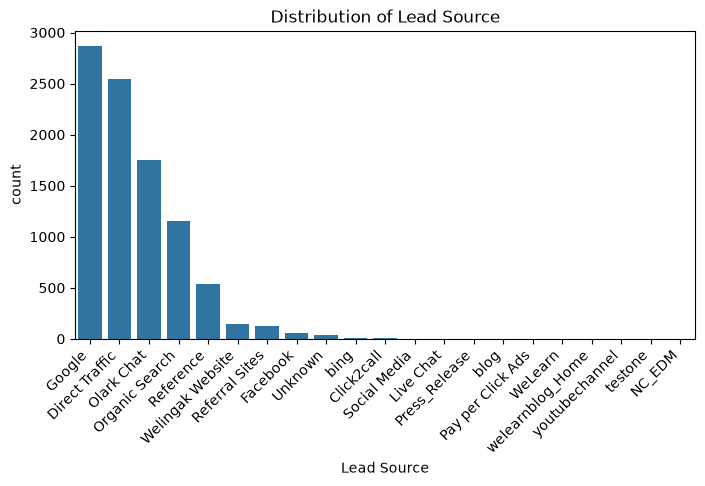

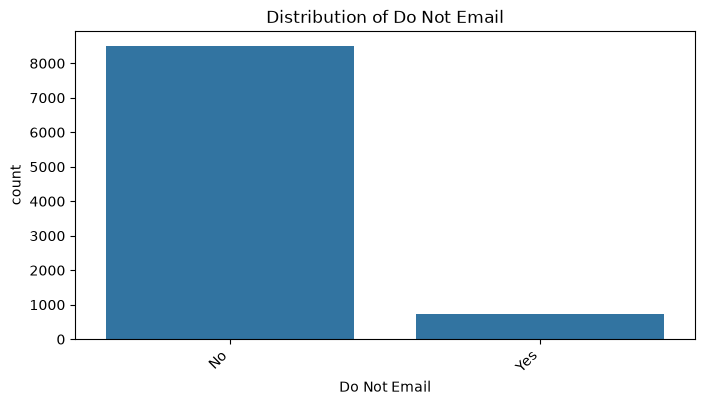

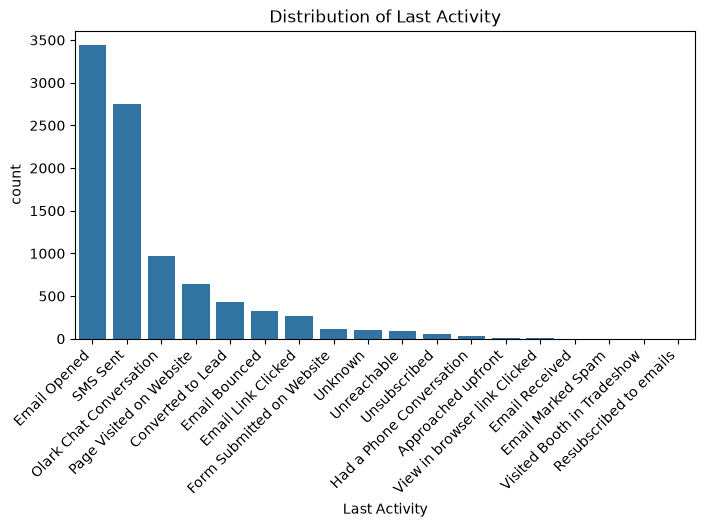

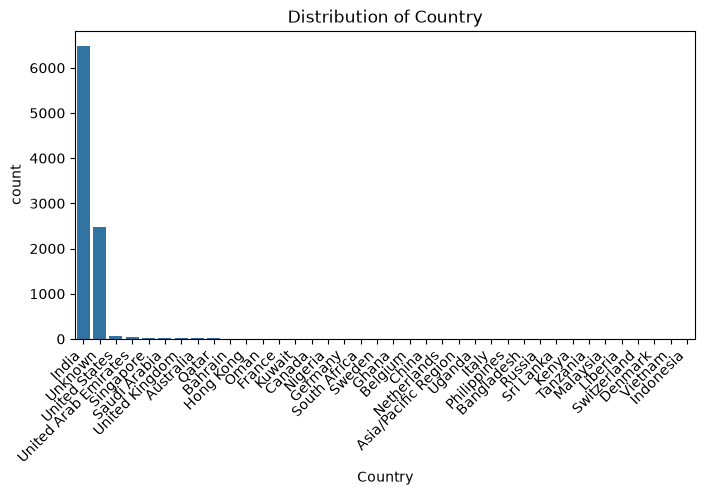

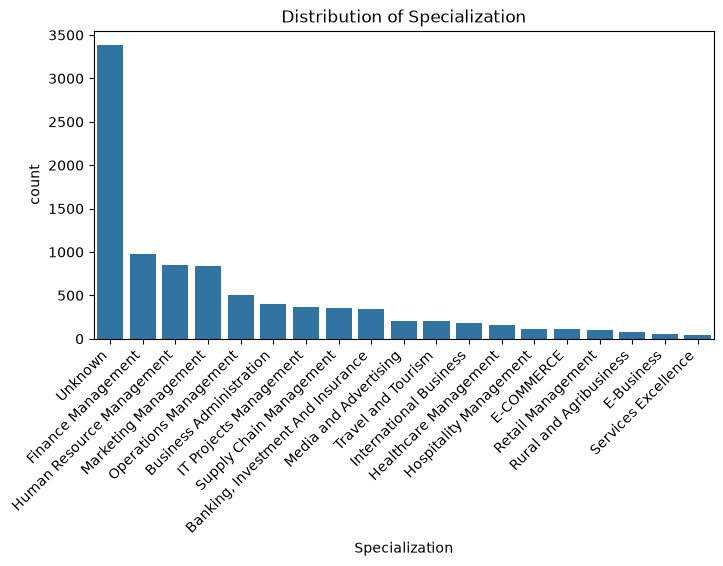

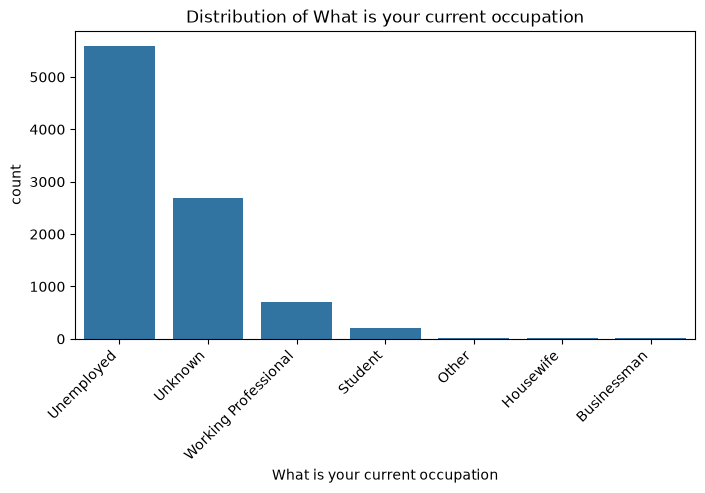

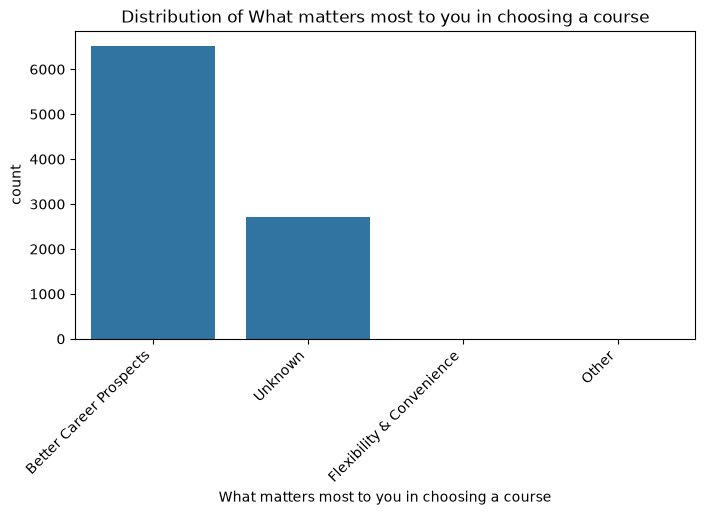

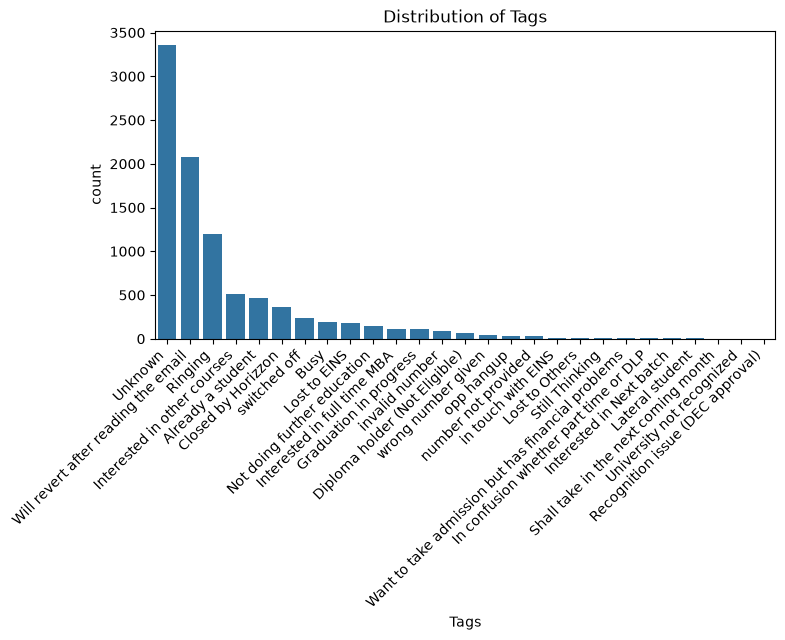

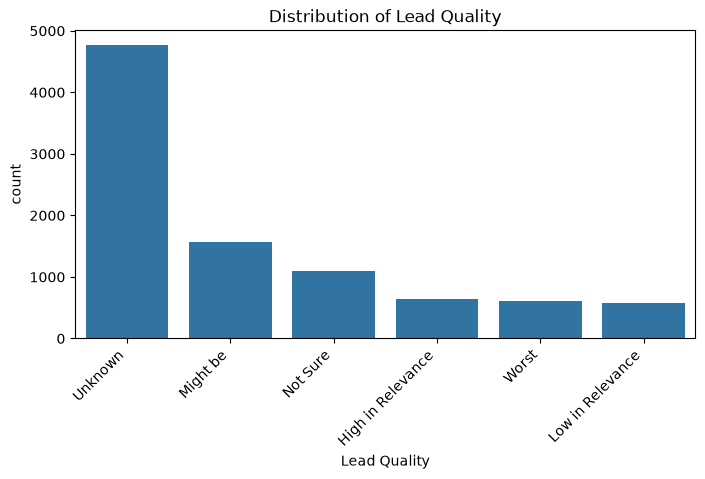

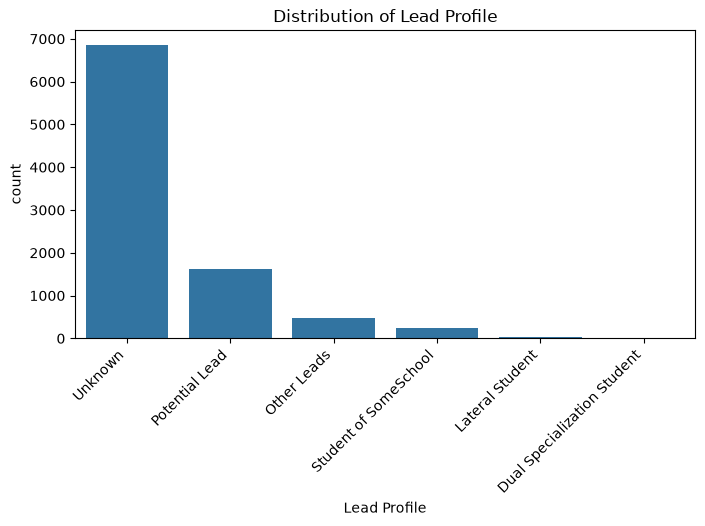

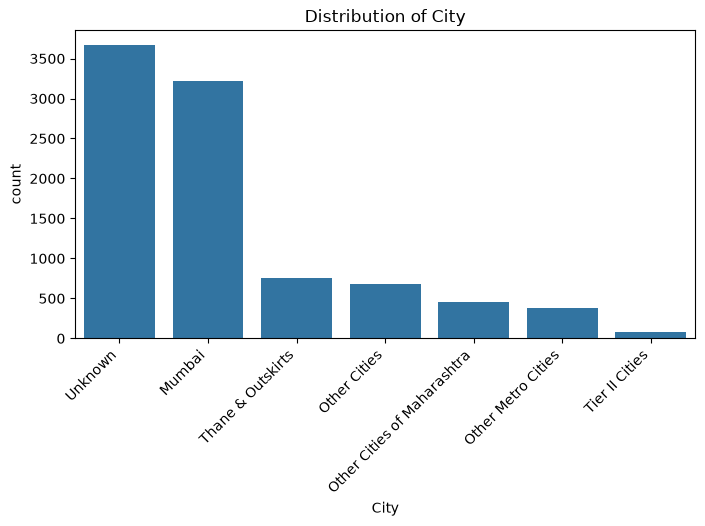

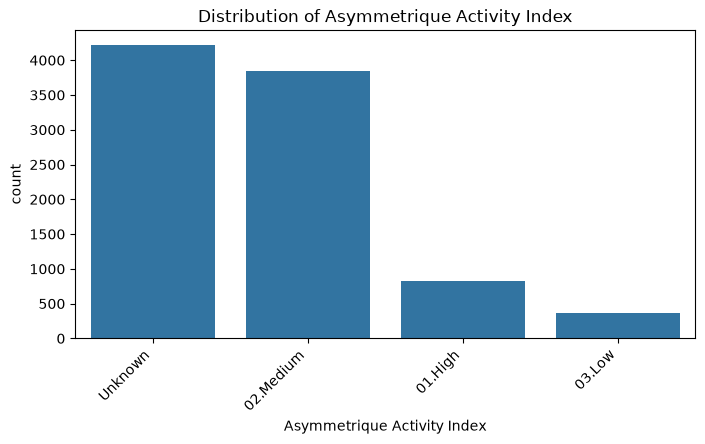

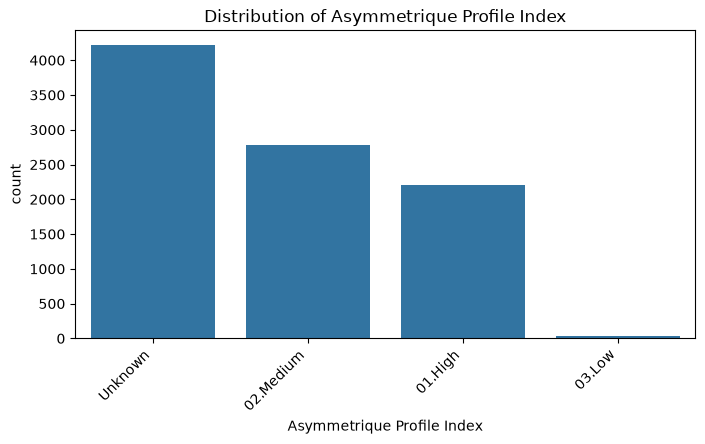

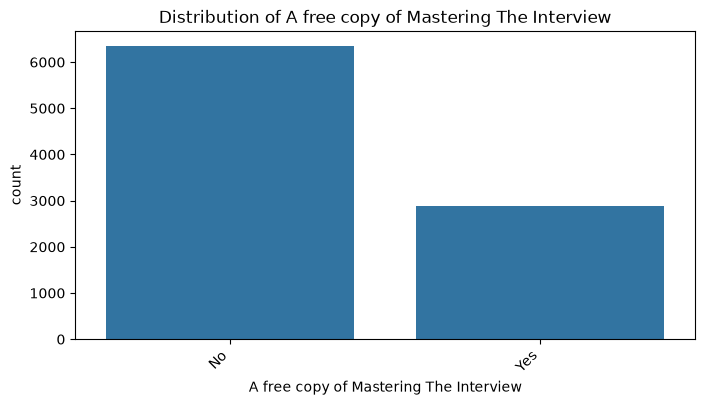

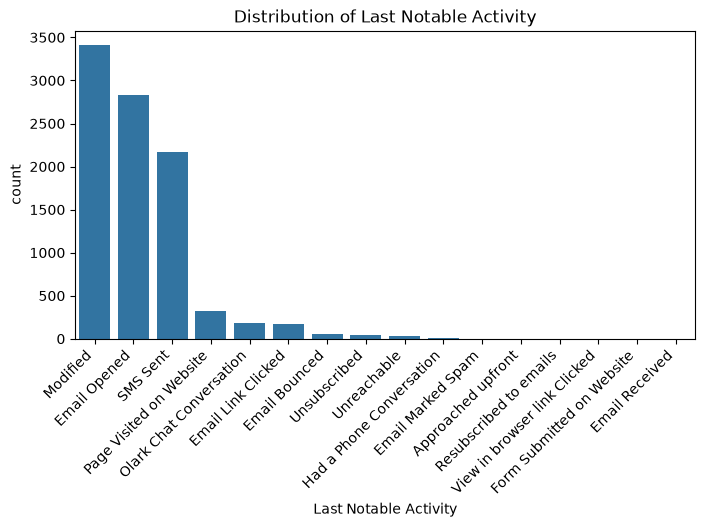

In [41]:
cat_cols = df.select_dtypes(include="object").columns

for col in cat_cols:
    plt.figure(figsize=(8, 4))
    sns.countplot(data=df, x=col, order=df[col].value_counts().index)
    plt.title(f"Distribution of {col}")
    plt.xticks(rotation=45, ha="right")
    plt.show()

##### Bivariate analysis

1. Numerical variables vs Converted

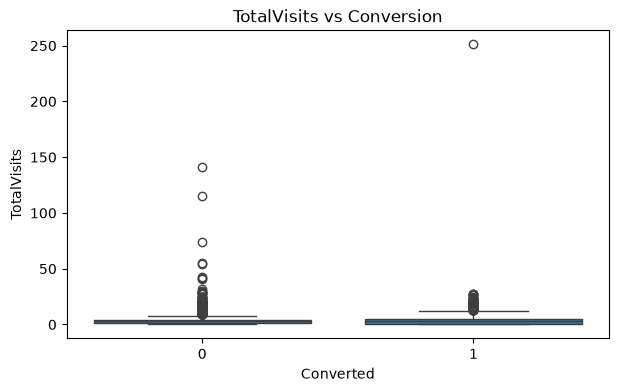

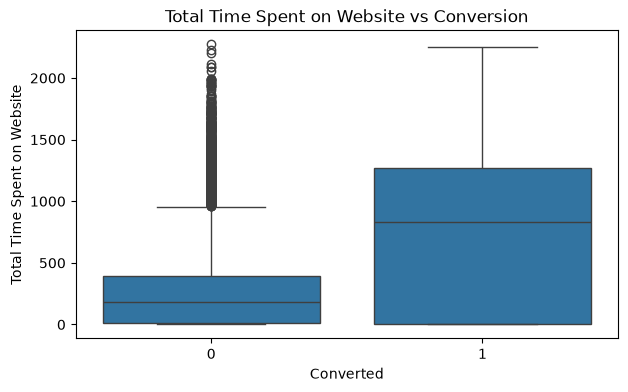

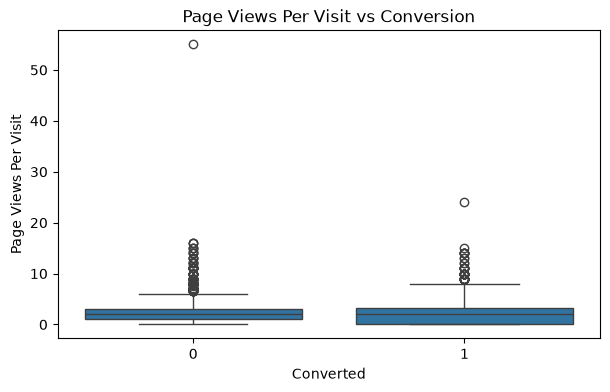

In [42]:
num_cols = ["TotalVisits", "Total Time Spent on Website", "Page Views Per Visit"]

for col in num_cols:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=df, x="Converted", y=col)
    plt.title(f"{col} vs Conversion")
    plt.xlabel("Converted")
    plt.ylabel(col)
    plt.show()

In [43]:
df.groupby("Converted")[num_cols].mean()

,TotalVisits,Total Time Spent on Website,Page Views Per Visit
Converted,,,
0,3.327522,330.404473,2.366052
1,3.615838,738.546757,2.343707


##### 2. Categorical variables vs Converted

In [44]:
cat_cols = df.select_dtypes(include="object").columns

for col in cat_cols:
    conversion_rate = df.groupby(col)["Converted"].mean().sort_values(ascending=False) * 100
    
    print(f"\n{col}")
    print(conversion_rate)


Lead Origin
Lead Origin
Quick Add Form             100.000000
Lead Add Form               92.479109
Landing Page Submission     36.185018
API                         31.145251
Lead Import                 23.636364
Name: Converted, dtype: float64

Lead Source
Lead Source
Live Chat            100.000000
WeLearn              100.000000
NC_EDM               100.000000
Welingak Website      98.591549
Reference             91.760300
Unknown               80.555556
Click2call            75.000000
Social Media          50.000000
Google                39.923425
Organic Search        37.781629
Direct Traffic        32.166732
Olark Chat            25.527066
Referral Sites        24.800000
Facebook              23.636364
bing                  16.666667
Press_Release          0.000000
Pay per Click Ads      0.000000
blog                   0.000000
testone                0.000000
welearnblog_Home       0.000000
youtubechannel         0.000000
Name: Converted, dtype: float64

Do Not Email
Do Not Ema

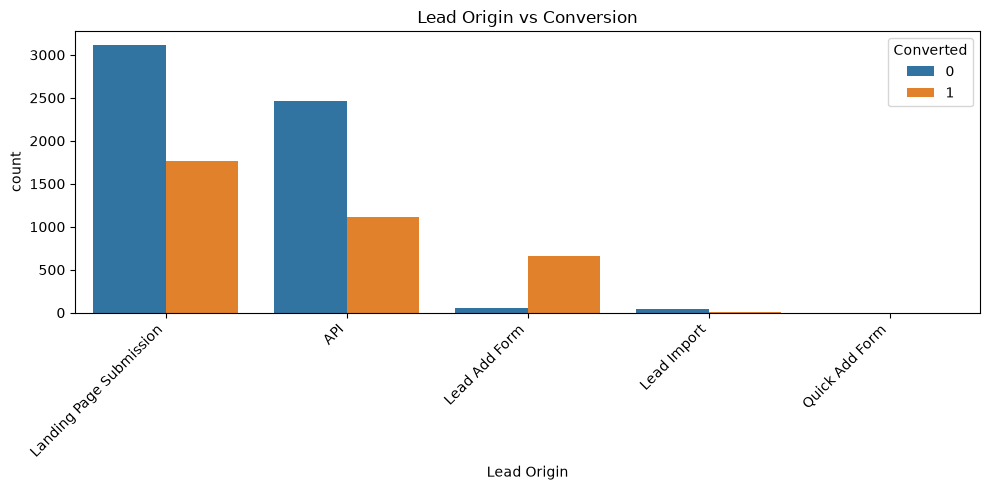

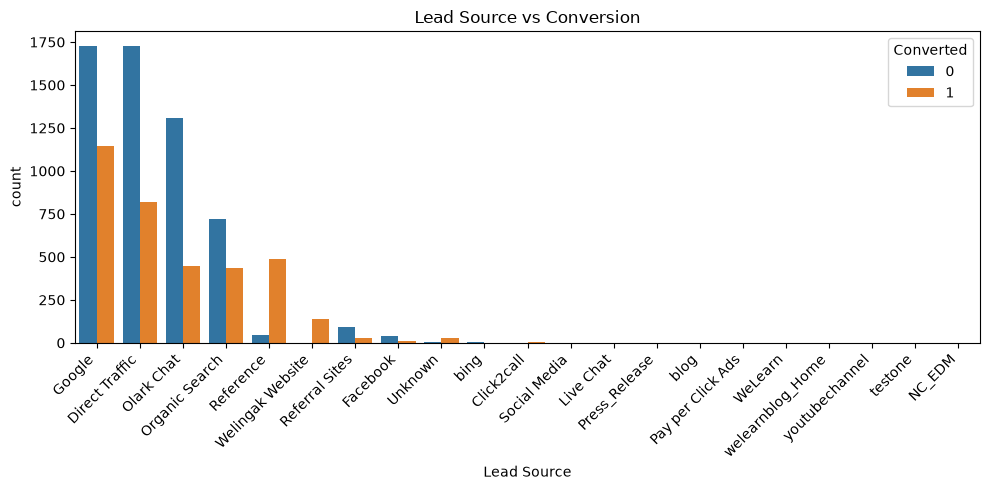

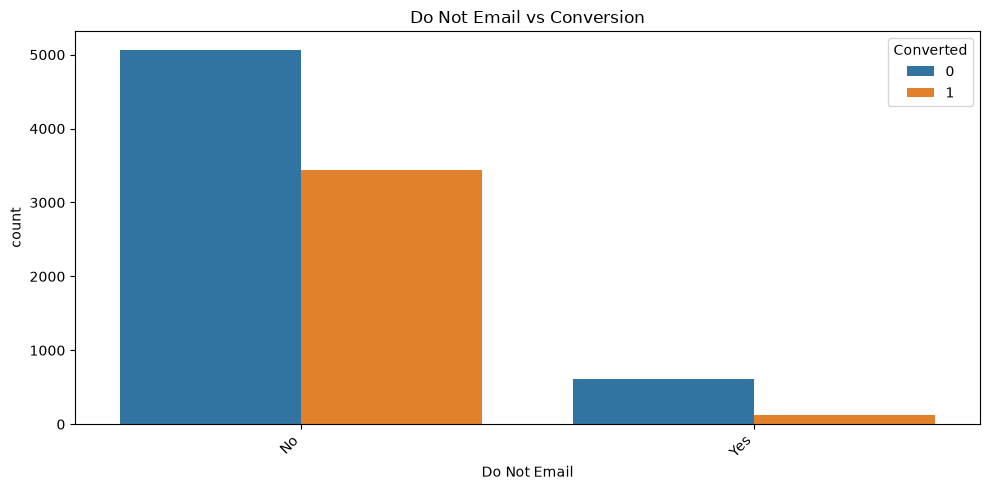

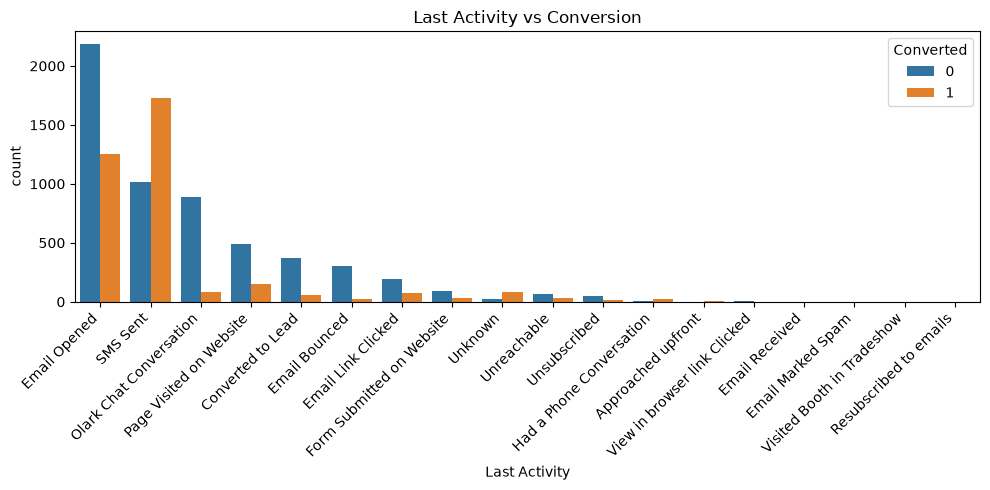

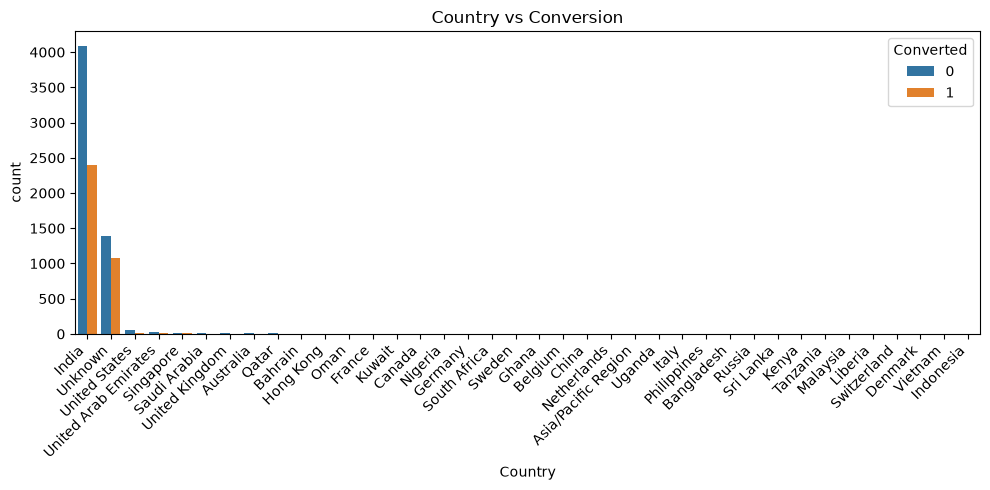

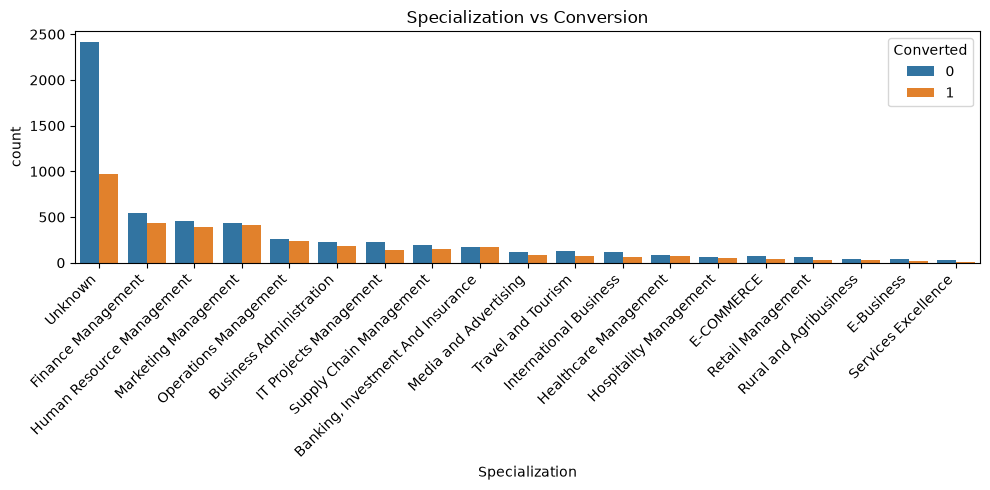

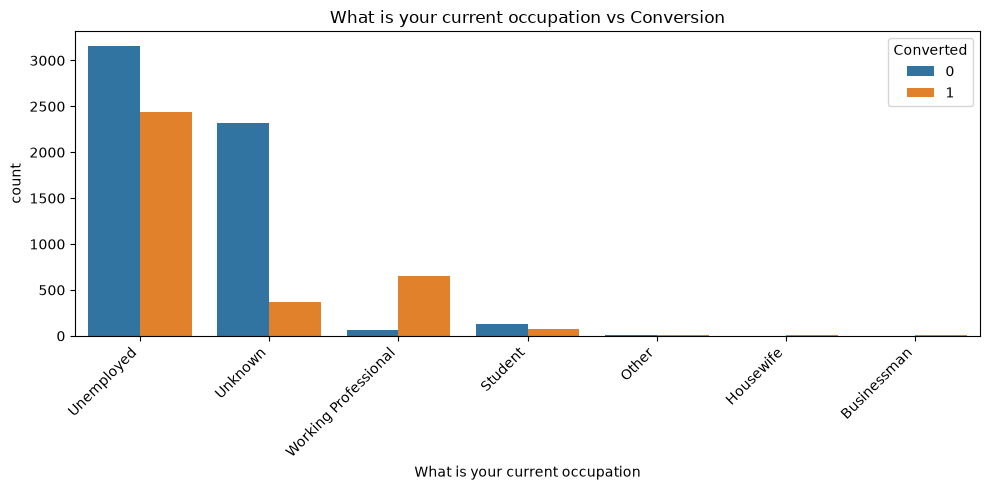

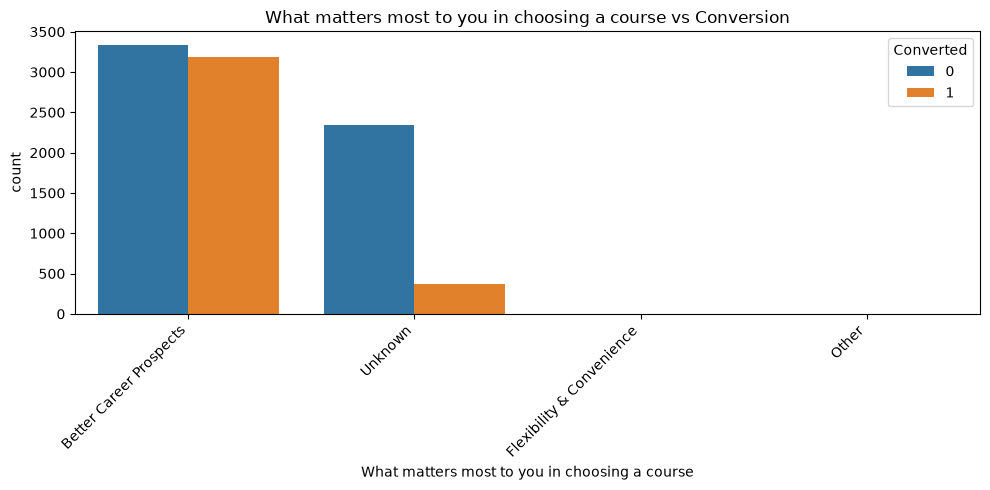

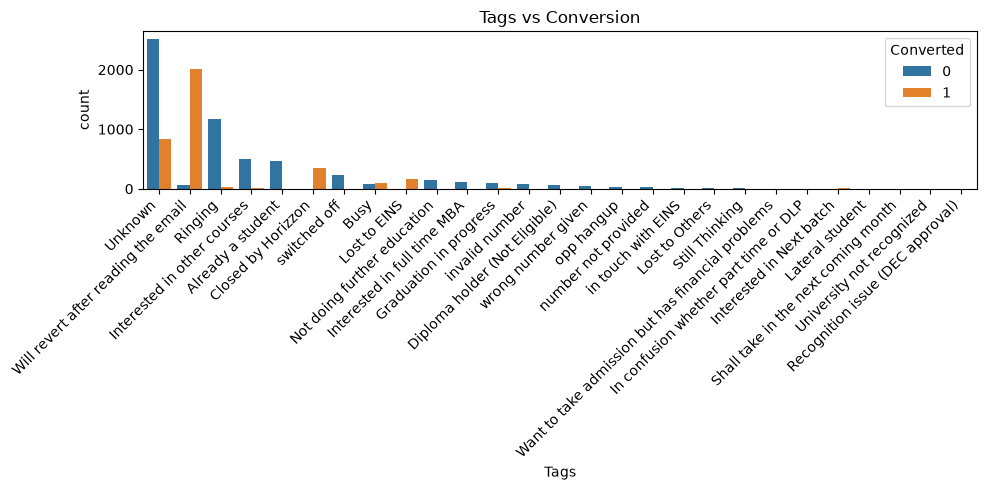

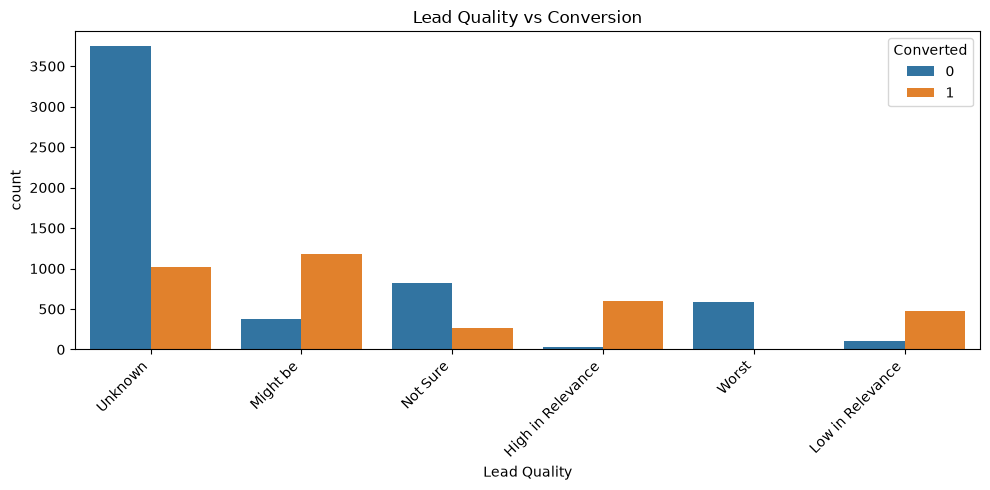

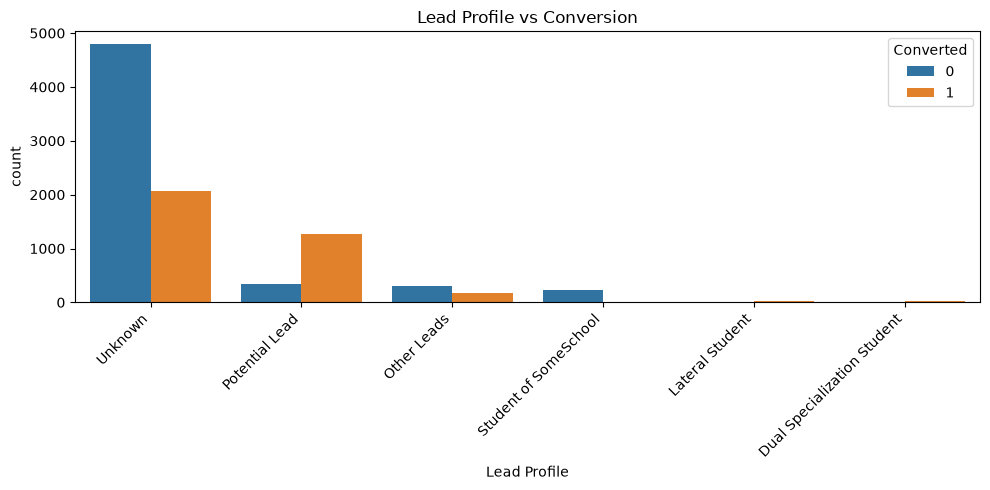

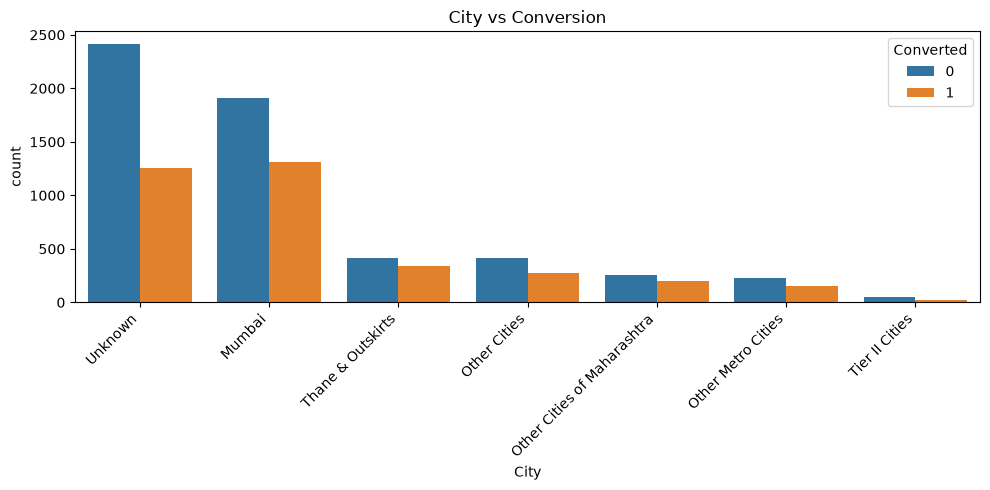

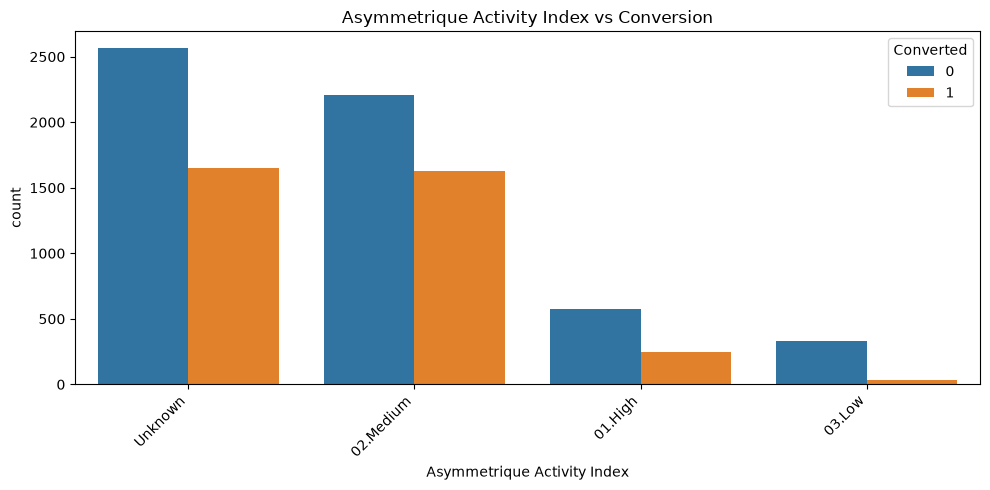

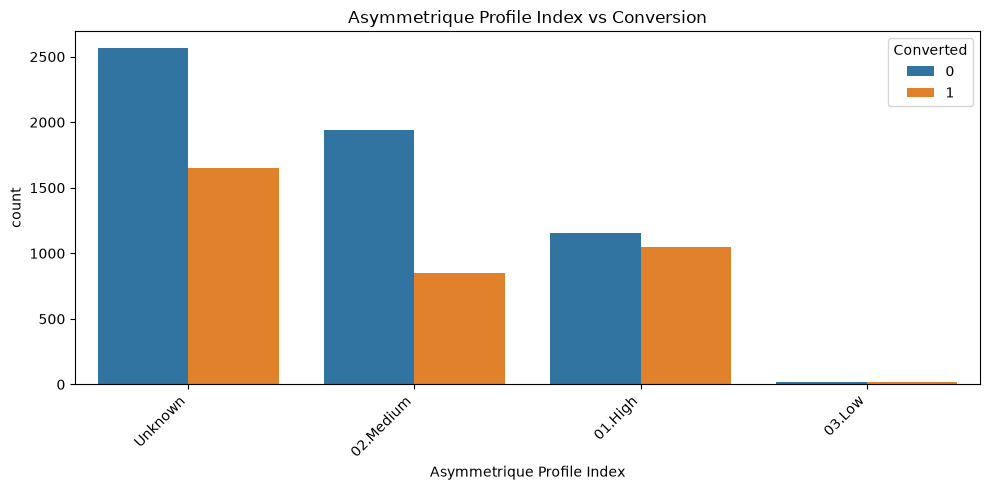

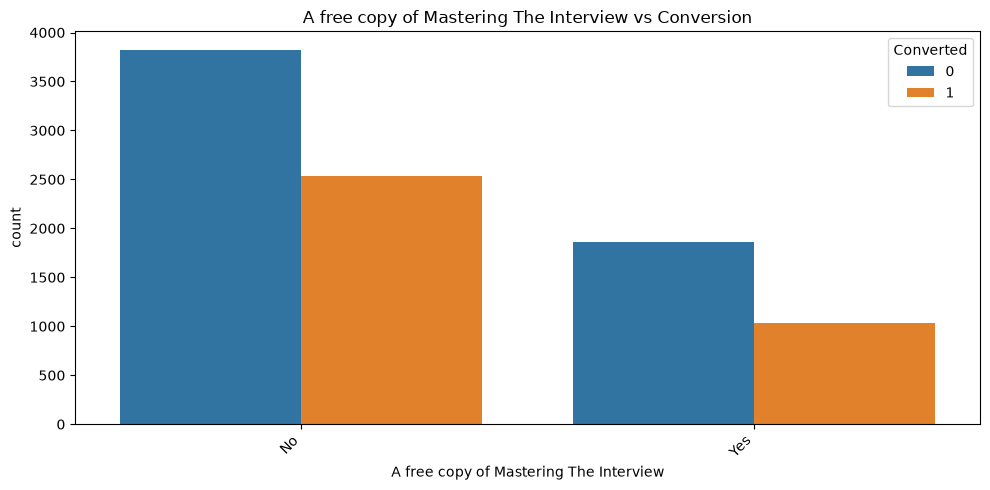

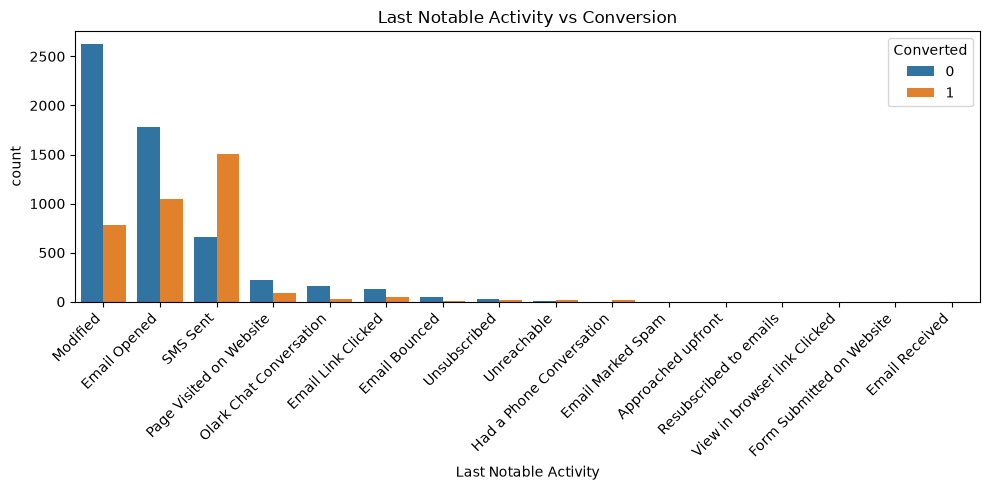

In [45]:
cat_cols = df.select_dtypes(include="object").columns

for col in cat_cols:
    plt.figure(figsize=(10, 5))
    sns.countplot(
        data=df,
        x=col,
        hue="Converted",
        order=df[col].value_counts().index
    )
    plt.title(f"{col} vs Conversion")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

* It was observed that among the converted leads, most leads are from **Mumbai**, and **Google** is the most common lead source. Most converted leads are **unemployed**, from **India**, and are looking for **better career prospects**.

.

##### Multivaraite Analysis

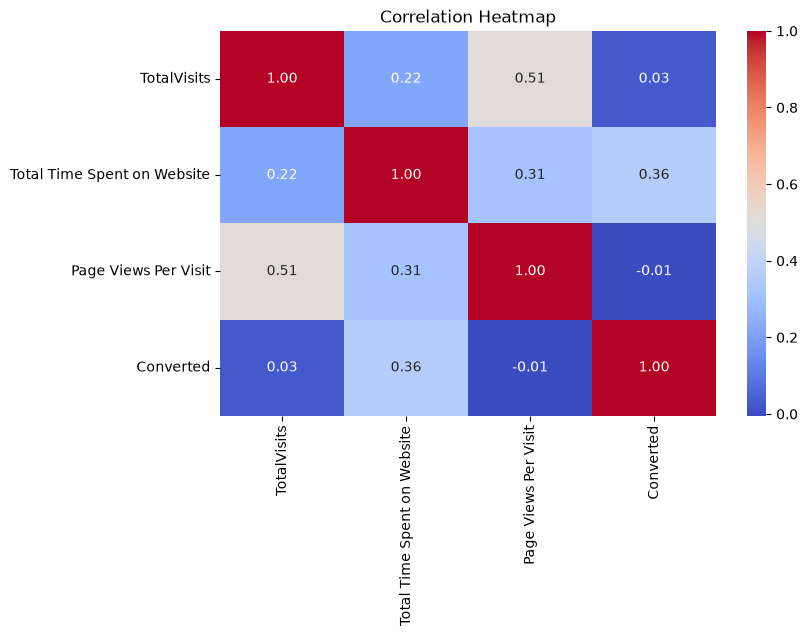

In [46]:
# Multivariate analysis using correlation heatmap

num_cols = ["TotalVisits", "Total Time Spent on Website", "Page Views Per Visit", "Converted"]

plt.figure(figsize=(8, 5))
sns.heatmap(df[num_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

- No strong correlation was observed between the numerical variables and the target variable (Converted).

#### 3. Train-Test split

In [47]:
from sklearn.model_selection import train_test_split

# Separate predictors and target
X = df.drop("Converted", axis=1)
y = df["Converted"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (7392, 19)
X_test: (1848, 19)
y_train: (7392,)
y_test: (1848,)


In [48]:
num_cols = [
    "TotalVisits",
    "Total Time Spent on Website",
    "Page Views Per Visit"
]

In [49]:
# Create dummy variables for categorical columns
cat_cols = X_train.select_dtypes(include="object").columns

X_train = pd.get_dummies(
    X_train,
    columns=cat_cols,
    drop_first=True,
    dtype=int
)

X_test = pd.get_dummies(
    X_test,
    columns=cat_cols,
    drop_first=True,
    dtype=int
)

# Make sure X_test has exactly the same columns as X_train
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print(X_train.shape)
print(X_test.shape)

(7392, 162)
(1848, 162)


In [50]:
# Scale numerical variables using StandardScaler
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Standardize numerical predictor variables using the training data
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

In [51]:
pd.set_option("display.max_columns", None)
print(X_train.head(2))

      TotalVisits  Total Time Spent on Website  Page Views Per Visit  \
9067    -0.291542                    -0.284643             -0.167231   
6093    -0.084243                    -0.134856             -0.396438   

      Lead Origin_Landing Page Submission  Lead Origin_Lead Add Form  \
9067                                    1                          0   
6093                                    0                          0   

      Lead Origin_Lead Import  Lead Origin_Quick Add Form  \
9067                        0                           0   
6093                        0                           0   

      Lead Source_Direct Traffic  Lead Source_Facebook  Lead Source_Google  \
9067                           0                     0                   1   
6093                           0                     0                   1   

      Lead Source_Live Chat  Lead Source_Olark Chat  \
9067                      0                       0   
6093                      0          

#### Model Building

In [52]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix
)

def evaluate_model(X_train, y_train, X_test, y_test, model=None, label=""):
    """
    Fits a Logistic Regression model (or uses one passed in),
    prints train/test metrics, and returns the fitted model
    plus predicted probabilities for further use (thresholding, decile analysis, etc.)
    """
    if model is None:
        model = LogisticRegression(max_iter=1000)
        model.fit(X_train, y_train)

    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)
    y_train_prob = model.predict_proba(X_train)[:, 1]
    y_test_prob = model.predict_proba(X_test)[:, 1]

    print(f"--- {label} ---")
    print("TRAIN  | Acc: {:.3f}  Prec: {:.3f}  Recall: {:.3f}  F1: {:.3f}  ROC-AUC: {:.3f}".format(
        accuracy_score(y_train, y_train_pred),
        precision_score(y_train, y_train_pred),
        recall_score(y_train, y_train_pred),
        f1_score(y_train, y_train_pred),
        roc_auc_score(y_train, y_train_prob)
    ))
    print("TEST   | Acc: {:.3f}  Prec: {:.3f}  Recall: {:.3f}  F1: {:.3f}  ROC-AUC: {:.3f}".format(
        accuracy_score(y_test, y_test_pred),
        precision_score(y_test, y_test_pred),
        recall_score(y_test, y_test_pred),
        f1_score(y_test, y_test_pred),
        roc_auc_score(y_test, y_test_prob)
    ))
    print("Test Confusion Matrix:\n", confusion_matrix(y_test, y_test_pred))
    print()

    return model, y_train_prob, y_test_prob

#### Predictions and Evaluation

In [53]:
model1, y_train_prob1, y_test_prob1 = evaluate_model(
    X_train, y_train, X_test, y_test, label="Model 1 (with Tags)"
)

--- Model 1 (with Tags) ---
TRAIN  | Acc: 0.944  Prec: 0.941  Recall: 0.913  F1: 0.927  ROC-AUC: 0.984
TEST   | Acc: 0.932  Prec: 0.926  Recall: 0.895  F1: 0.910  ROC-AUC: 0.976
Test Confusion Matrix:
 [[1085   51]
 [  75  637]]



In [54]:
# Get feature names
feature_names = X_train.columns

# Get coefficients
coefficients = model1.coef_[0]

# Create a dataframe
coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Sort by coefficient
coef_df = coef_df.sort_values("Coefficient", ascending=False)

print(coef_df)

                                      Feature  Coefficient
109                         Tags_Lost to EINS     6.544338
101                   Tags_Closed by Horizzon     5.495273
119  Tags_Will revert after reading the email     4.578585
117                              Tags_Unknown     2.657945
18               Lead Source_Welingak Website     1.591927
..                                        ...          ...
125                   Tags_wrong number given    -1.704802
122                  Tags_number not provided    -1.721933
130                        Lead Quality_Worst    -2.456857
113                              Tags_Ringing    -2.477379
124                         Tags_switched off    -2.793012

[162 rows x 2 columns]


In [55]:
pd.crosstab(
    df["Tags"],
    df["Converted"],
    normalize="index"
).sort_values(1, ascending=False)

Converted,0,1
Tags,,
Interested in Next batch,0.000000,1.000000
Lateral student,0.000000,1.000000
Closed by Horizzon,0.005587,0.994413
Lost to EINS,0.022857,0.977143
Will revert after reading the email,0.031371,0.968629
Busy,0.435484,0.564516
Shall take in the next coming month,0.500000,0.500000
Want to take admission but has financial problems,0.666667,0.333333
in touch with EINS,0.750000,0.250000


In [56]:
pd.crosstab(df["Tags"], df["Converted"])

Converted,0,1
Tags,,
Already a student,462,3
Busy,81,105
Closed by Horizzon,2,356
Diploma holder (Not Eligible),62,1
Graduation in progress,104,7
In confusion whether part time or DLP,4,1
Interested in Next batch,0,5
Interested in full time MBA,114,3
Interested in other courses,500,13


- Model1 includes Tags, which represents the current status of the lead and is extremely strongly associated with the target Converted.
To avoid using potentially post-outcome information, we exclude Tags and build Model 2 using features available earlier in the lead journey.

- For model2 repeating the process statrting from dropping the target and 'Tags' columns to model building

In [57]:
# Create X and y
X = df.drop(columns=["Converted", "Tags"])
y = df["Converted"]

In [58]:
from sklearn.model_selection import train_test_split

X_train2, X_test2, y_train2, y_test2 = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [59]:
cat_cols = X_train2.select_dtypes(include="object").columns

X_train2 = pd.get_dummies(
    X_train2,
    columns=cat_cols,
    drop_first=True,
    dtype=int
)

X_test2 = pd.get_dummies(
    X_test2,
    columns=cat_cols,
    drop_first=True,
    dtype=int
)

# Make columns identical
X_test2 = X_test2.reindex(
    columns=X_train2.columns,
    fill_value=0
)

In [60]:
from sklearn.preprocessing import StandardScaler

num_cols = [
    "TotalVisits",
    "Total Time Spent on Website",
    "Page Views Per Visit"
]

scaler2 = StandardScaler()

X_train2[num_cols] = scaler2.fit_transform(X_train2[num_cols])
X_test2[num_cols] = scaler2.transform(X_test2[num_cols])

In [61]:
model2, y_train_prob2, y_test_prob2 = evaluate_model(
    X_train2, y_train2, X_test2, y_test2, label="Model 2 (without Tags)"
)

--- Model 2 (without Tags) ---
TRAIN  | Acc: 0.868  Prec: 0.852  Recall: 0.796  F1: 0.823  ROC-AUC: 0.938
TEST   | Acc: 0.834  Prec: 0.797  Recall: 0.765  F1: 0.781  ROC-AUC: 0.909
Test Confusion Matrix:
 [[997 139]
 [167 545]]



In [62]:
# Get feature names and coefficients
coef_df2 = pd.DataFrame({
    "Feature": X_train2.columns,
    "Coefficient": model2.coef_[0]
})

# Sort by coefficient
coef_df2 = coef_df2.sort_values("Coefficient", ascending=False)

print(coef_df2)

                                               Feature  Coefficient
18                        Lead Source_Welingak Website     2.292567
4                            Lead Origin_Lead Add Form     1.533390
72                                     Country_Unknown     1.330178
134                  Last Notable Activity_Unreachable     1.170821
97   What is your current occupation_Working Profes...     1.151635
..                                                 ...          ...
101                              Lead Quality_Might be    -1.301728
117                 Asymmetrique Activity Index_03.Low    -2.116909
103                               Lead Quality_Unknown    -2.488024
102                              Lead Quality_Not Sure    -3.253483
104                                 Lead Quality_Worst    -4.939016

[136 rows x 2 columns]


In [63]:
print("Top Positive Features:")
print(coef_df2.head(10))

print("\nTop Negative Features:")
print(coef_df2.tail(10))

Top Positive Features:
                                               Feature  Coefficient
18                        Lead Source_Welingak Website     2.292567
4                            Lead Origin_Lead Add Form     1.533390
72                                     Country_Unknown     1.330178
134                  Last Notable Activity_Unreachable     1.170821
97   What is your current occupation_Working Profes...     1.151635
1                          Total Time Spent on Website     1.105238
128     Last Notable Activity_Had a Phone Conversation     1.005532
92           What is your current occupation_Housewife     0.913496
33                              Last Activity_SMS Sent     0.893260
69                        Country_United Arab Emirates     0.698109

Top Negative Features:
                                               Feature  Coefficient
99   What matters most to you in choosing a course_...    -0.927919
62                                Country_Saudi Arabia    -0.981673
3

Variance Inflation Factor (VIF)

In [64]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

def calculate_vif(X):
    """
    Computes VIF for every column in X (should be numeric-only,
    e.g. your dummy-encoded / scaled feature set before adding a constant).
    Returns a DataFrame sorted by VIF, highest first.
    """
    vif_df = pd.DataFrame()
    vif_df["Feature"] = X.columns
    vif_df["VIF"] = [
        variance_inflation_factor(X.values, i) for i in range(X.shape[1])
    ]
    return vif_df.sort_values("VIF", ascending=False).reset_index(drop=True)

In [65]:
vif2 = calculate_vif(X_train2)
vif2

,Feature,VIF
0,Asymmetrique Profile Index_Unknown,inf
1,Last Notable Activity_Email Received,inf
2,Last Notable Activity_Resubscribed to emails,inf
3,Asymmetrique Activity Index_Unknown,inf
4,Last Activity_Email Received,inf
...,...,...
131,Asymmetrique Profile Index_03.Low,1.173922
132,Last Activity_Visited Booth in Tradeshow,1.172930
133,Specialization_Services Excellence,1.158635
134,City_Tier II Cities,1.054580


In [66]:
pd.crosstab(
    df["Last Activity"],
    df["Last Notable Activity"],
    normalize="index"
)

Last Notable Activity,Approached upfront,Email Bounced,Email Link Clicked,Email Marked Spam,Email Opened,Email Received,Form Submitted on Website,Had a Phone Conversation,Modified,Olark Chat Conversation,Page Visited on Website,Resubscribed to emails,SMS Sent,Unreachable,Unsubscribed,View in browser link Clicked
Last Activity,,,,,,,,,,,,,,,,
Approached upfront,0.111111,0.000000,0.00000,0.0,0.00000,0.0,0.000000,0.000000,0.888889,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000
Converted to Lead,0.000000,0.000000,0.00000,0.0,0.00000,0.0,0.000000,0.000000,1.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000
Email Bounced,0.000000,0.184049,0.00000,0.0,0.00000,0.0,0.000000,0.000000,0.815951,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000
Email Link Clicked,0.000000,0.000000,0.64794,0.0,0.00000,0.0,0.000000,0.000000,0.352060,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000
Email Marked Spam,0.000000,0.000000,0.00000,1.0,0.00000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000
Email Opened,0.000000,0.000000,0.00000,0.0,0.82252,0.0,0.000000,0.000000,0.177480,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000
Email Received,0.000000,0.000000,0.00000,0.0,0.00000,0.5,0.000000,0.000000,0.500000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000
Form Submitted on Website,0.000000,0.000000,0.00000,0.0,0.00000,0.0,0.008621,0.000000,0.991379,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000
Had a Phone Conversation,0.000000,0.000000,0.00000,0.0,0.00000,0.0,0.000000,0.466667,0.533333,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000


- Feature selection based on vif

##### Dropping Redundant Activity Features

`Last Activity` and `Last Notable Activity` contain overlapping information about the lead's recent interaction with the platform. Both variables also showed high VIF values, indicating strong multicollinearity. To reduce redundant information and improve model stability, `Last Notable Activity` was removed while retaining `Last Activity`.


In [67]:
#dropping all the dummy columns belonging to Last Notable Activity
cols_to_drop = [
    col for col in X_train2.columns
    if col.startswith("Last Notable Activity_")
]

X_train3 = X_train2.drop(columns=cols_to_drop)
X_test3 = X_test2.drop(columns=cols_to_drop)

In [68]:
print(X_train3.shape)
print(X_test3.shape)

(7392, 123)
(1848, 123)


In [69]:
vif3 = calculate_vif(X_train3)
vif3

,Feature,VIF
0,Asymmetrique Profile Index_Unknown,inf
1,Asymmetrique Activity Index_Unknown,inf
2,Country_India,3542.692620
3,Lead Source_Google,1764.611946
4,Lead Source_Direct Traffic,1574.827434
...,...,...
118,Last Activity_Email Received,1.146269
119,Last Activity_Visited Booth in Tradeshow,1.142868
120,Last Activity_Resubscribed to emails,1.140907
121,City_Tier II Cities,1.053409


In [70]:
X_train3.shape, X_test3.shape

((7392, 123), (1848, 123))

In [71]:
#check the relationship between the two original variables
pd.crosstab(
    df["Asymmetrique Profile Index"],
    df["Asymmetrique Activity Index"],
    normalize="index"
)

Asymmetrique Activity Index,01.High,02.Medium,03.Low,Unknown
Asymmetrique Profile Index,,,,
01.High,0.078529,0.850204,0.071266,0.0
02.Medium,0.229914,0.697633,0.072453,0.0
03.Low,0.225806,0.677419,0.096774,0.0
Unknown,0.000000,0.000000,0.000000,1.0


- The crosstab shows that Asymmetrique Profile Index = Unknown always occurs with Asymmetrique Activity Index = Unknown, indicating perfect overlap in their missing categories. Therefore, one of these features can be removed to reduce multicollinearity.

In [72]:
cols_to_drop = [
    col for col in X_train3.columns
    if col.startswith("Asymmetrique Activity Index_")
]

X_train4 = X_train3.drop(columns=cols_to_drop)
X_test4 = X_test3.drop(columns=cols_to_drop)

In [73]:
X_train4.shape, X_test4.shape

((7392, 120), (1848, 120))

In [74]:
model3, y_train_prob3, y_test_prob3 = evaluate_model(
    X_train4, y_train2, X_test4, y_test2, label="Model 3 (VIF: dropped Last Notable Activity)"
)

--- Model 3 (VIF: dropped Last Notable Activity) ---
TRAIN  | Acc: 0.861  Prec: 0.842  Recall: 0.787  F1: 0.813  ROC-AUC: 0.934
TEST   | Acc: 0.829  Prec: 0.790  Recall: 0.757  F1: 0.773  ROC-AUC: 0.902
Test Confusion Matrix:
 [[993 143]
 [173 539]]



In [75]:
vif4 = calculate_vif(X_train4)
vif4

,Feature,VIF
0,Country_India,3542.283585
1,Lead Source_Google,1761.602774
2,Lead Source_Direct Traffic,1572.206786
3,Country_Unknown,1357.207318
4,Lead Source_Olark Chat,1077.231313
...,...,...
115,Last Activity_Email Received,1.146231
116,Last Activity_Visited Booth in Tradeshow,1.142837
117,Last Activity_Resubscribed to emails,1.140891
118,City_Tier II Cities,1.053398


In [76]:
pd.crosstab(
    df["Lead Origin"],
    df["Lead Source"],
    normalize="index"
)

Lead Source,Click2call,Direct Traffic,Facebook,Google,Live Chat,NC_EDM,Olark Chat,Organic Search,Pay per Click Ads,Press_Release,Reference,Referral Sites,Social Media,Unknown,WeLearn,Welingak Website,bing,blog,testone,welearnblog_Home,youtubechannel
Lead Origin,,,,,,,,,,,,,,,,,,,,,
API,0.000000,0.030726,0.000000,0.323464,0.000000,0.000000,0.489665,0.127374,0.000000,0.000000,0.000000,0.027374,0.000279,0.000000,0.000000,0.000000,0.001117,0.000000,0.000000,0.000000,0.000000
Landing Page Submission,0.000000,0.497953,0.000205,0.350798,0.000000,0.000205,0.000000,0.142857,0.000205,0.000409,0.000000,0.005526,0.000205,0.000205,0.000205,0.000000,0.000409,0.000205,0.000205,0.000205,0.000205
Lead Add Form,0.005571,0.000000,0.000000,0.001393,0.002786,0.000000,0.002786,0.000000,0.000000,0.000000,0.743733,0.000000,0.000000,0.045961,0.000000,0.197772,0.000000,0.000000,0.000000,0.000000,0.000000
Lead Import,0.000000,0.000000,0.981818,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.018182,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Quick Add Form,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [77]:
df["Lead Source"].value_counts()

Lead Source
Google               2873
Direct Traffic       2543
Olark Chat           1755
Organic Search       1154
Reference             534
Welingak Website      142
Referral Sites        125
Facebook               55
Unknown                36
bing                    6
Click2call              4
Social Media            2
Live Chat               2
Press_Release           2
blog                    1
Pay per Click Ads       1
WeLearn                 1
welearnblog_Home        1
youtubechannel          1
testone                 1
NC_EDM                  1
Name: count, dtype: int64

##### Dropping Redundant Lead Features

`Lead Source` and `Lead Origin` provide related information about how a lead entered the X Education system. The variables showed substantial overlap and high VIF values, indicating multicollinearity. To reduce redundant information and improve model stability, `Lead Source` was removed while retaining `Lead Origin`.


In [78]:
cols_to_drop = [
    col for col in X_train4.columns
    if col.startswith("Lead Source_")
]

X_train5 = X_train4.drop(columns=cols_to_drop)
X_test5 = X_test4.drop(columns=cols_to_drop)

In [143]:
model4, y_train_prob4, y_test_prob4 = evaluate_model(
    X_train5, y_train2, X_test5, y_test2, label="Model 4 (VIF: also dropped Lead Source dummy columns)"
)

--- Model 4 (VIF: also dropped Lead Source dummy columns) ---
TRAIN  | Acc: 0.861  Prec: 0.842  Recall: 0.788  F1: 0.814  ROC-AUC: 0.932
TEST   | Acc: 0.825  Prec: 0.783  Recall: 0.756  F1: 0.769  ROC-AUC: 0.901
Test Confusion Matrix:
 [[987 149]
 [174 538]]



In [80]:
vif5 = calculate_vif(X_train5)
vif5

,Feature,VIF
0,Country_India,1428.619747
1,What is your current occupation_Unemployed,590.216148
2,Country_Unknown,541.845777
3,Lead Profile_Unknown,412.505910
4,What is your current occupation_Unknown,398.916210
...,...,...
100,Last Activity_Visited Booth in Tradeshow,1.133766
101,Last Activity_Resubscribed to emails,1.132192
102,City_Tier II Cities,1.051486
103,Lead Origin_Quick Add Form,1.026108


In [81]:
df["Country"].value_counts()

Country
India                   6492
Unknown                 2466
United States             69
United Arab Emirates      53
Singapore                 24
Saudi Arabia              21
United Kingdom            15
Australia                 13
Qatar                     10
Bahrain                    7
Hong Kong                  7
Oman                       6
France                     6
Kuwait                     4
Canada                     4
Nigeria                    4
Germany                    4
South Africa               4
Sweden                     3
Ghana                      2
Belgium                    2
China                      2
Netherlands                2
Asia/Pacific Region        2
Uganda                     2
Italy                      2
Philippines                2
Bangladesh                 2
Russia                     1
Sri Lanka                  1
Kenya                      1
Tanzania                   1
Malaysia                   1
Liberia                    1
Switze

In [82]:
pd.crosstab(df["Country"], df["Converted"], normalize="index")

Converted,0,1
Country,,
Asia/Pacific Region,0.500000,0.500000
Australia,0.769231,0.230769
Bahrain,0.428571,0.571429
Bangladesh,0.500000,0.500000
Belgium,1.000000,0.000000
Canada,1.000000,0.000000
China,1.000000,0.000000
Denmark,0.000000,1.000000
France,0.500000,0.500000


In [83]:
pd.crosstab(df["City"], df["Country"])

Country,Asia/Pacific Region,Australia,Bahrain,Bangladesh,Belgium,Canada,China,Denmark,France,Germany,Ghana,Hong Kong,India,Indonesia,Italy,Kenya,Kuwait,Liberia,Malaysia,Netherlands,Nigeria,Oman,Philippines,Qatar,Russia,Saudi Arabia,Singapore,South Africa,Sri Lanka,Sweden,Switzerland,Tanzania,Uganda,United Arab Emirates,United Kingdom,United States,Unknown,Vietnam
City,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
Mumbai,0,6,1,0,1,3,1,0,0,1,0,2,2918,0,0,0,2,0,0,1,0,2,1,3,0,7,6,0,0,1,1,0,0,17,6,30,211,1
Other Cities,0,2,2,2,0,0,0,1,2,1,1,2,564,0,1,1,2,0,0,0,3,2,1,2,0,9,4,3,0,0,0,0,1,19,0,6,55,0
Other Cities of Maharashtra,0,0,1,0,0,0,0,0,2,1,0,2,391,1,0,0,0,0,1,0,0,0,0,1,0,2,2,0,0,0,0,0,0,3,2,5,43,0
Other Metro Cities,0,0,0,0,0,0,0,0,2,0,0,0,345,0,0,0,0,1,0,0,1,1,0,1,0,2,2,0,0,0,0,1,0,4,1,4,15,0
Thane & Outskirts,0,3,2,0,1,0,0,0,0,1,0,0,651,0,0,0,0,0,0,1,0,0,0,1,0,1,3,0,0,0,0,0,0,1,2,5,80,0
Tier II Cities,0,0,1,0,0,0,0,0,0,0,0,0,69,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,2,0
Unknown,2,2,0,0,0,1,1,0,0,0,1,1,1554,0,1,0,0,0,0,0,0,1,0,2,1,0,7,1,1,2,0,0,1,9,3,18,2060,0


##### Dropping Redundant Location Features

`City` and `Country` provide overlapping information about the lead's geographic location. The variables also showed high VIF values, indicating multicollinearity. To reduce redundant information and improve model stability, `Country` was removed while retaining `City`.


In [84]:
country_cols = [
    col for col in X_train5.columns
    if col.startswith("Country_")
]

X_train6 = X_train5.drop(columns=country_cols)
X_test6 = X_test5.drop(columns=country_cols)

In [85]:
X_train6.shape, X_test6.shape

((7392, 70), (1848, 70))

In [86]:
vif6 = calculate_vif(X_train6)
vif6.head(20)

,Feature,VIF
0,What is your current occupation_Unemployed,403.104819
1,Lead Profile_Unknown,343.451804
2,What is your current occupation_Unknown,322.434049
3,Last Activity_Email Opened,245.229677
4,Last Activity_SMS Sent,193.018634
5,What matters most to you in choosing a course_...,166.577298
6,Lead Profile_Potential Lead,81.970598
7,Last Activity_Olark Chat Conversation,69.065927
8,What is your current occupation_Working Profes...,51.354013
9,Last Activity_Page Visited on Website,47.634416


In [87]:
model5, y_train_prob5, y_test_prob5 = evaluate_model(
    X_train6, y_train2, X_test6, y_test2, label="Model 5 (VIF: also dropped Country)"
)

--- Model 5 (VIF: also dropped Country) ---
TRAIN  | Acc: 0.858  Prec: 0.842  Recall: 0.777  F1: 0.808  ROC-AUC: 0.930
TEST   | Acc: 0.817  Prec: 0.780  Recall: 0.732  F1: 0.755  ROC-AUC: 0.897
Test Confusion Matrix:
 [[989 147]
 [191 521]]



- Vif based feature removel is hurting the model so now we will do Statistical Significance Analysis.

##### Statistical Significance Analysis

- statsmodels.Logit is used to fit Logistic Regression with an intercept and obtain p-values for each feature.

- The p-values help identify which features have a statistically significant relationship with the target variable.

In [88]:
# Check for infinite or missing values
print(np.isinf(X_train5).sum().sum())
print(X_train5.isna().sum().sum())

0
0


In [89]:
import numpy as np

print("Number of columns:", X_train5.shape[1])
print("Matrix rank:", np.linalg.matrix_rank(X_train5.values))

Number of columns: 105
Matrix rank: 105


In [90]:
# import statsmodels.api as sm

# X_train_sm = sm.add_constant(X_train6)
# logit_model = sm.Logit(y_train2, X_train_sm)
# result = logit_model.fit()
# print(result.summary())

In [91]:
# import numpy as np

# # 1. Check for constant / zero-variance columns
# constant_cols = X_train6.columns[X_train6.nunique() <= 1]
# print("Constant columns:", list(constant_cols))

# # 2. Check for exact duplicate columns
# dupes = X_train6.T[X_train6.T.duplicated()].index.tolist()
# print("Duplicate columns:", dupes)

# # 3. Compare rank vs number of columns (including the constant)
# X_train_sm = sm.add_constant(X_train6)
# rank = np.linalg.matrix_rank(X_train_sm.values)
# print(f"Rank: {rank}, Columns: {X_train_sm.shape[1]}")

#### Statsmodels Logistic Regression Diagnostic

The Statsmodels Logistic Regression model did not converge and produced infinite log-likelihood values and `NaN` standard errors. This indicates **multicollinearity and possible quasi/perfect separation** among some predictor variables, particularly sparse categorical dummy variables. Therefore, the p-values and statistical significance from this model were not considered reliable. We addressed this by consolidating rare categories and reducing redundant/multicollinear features before proceeding with the final Logistic Regression model.


#### Multicollinearity Diagnostic

The feature matrix was checked for constant columns, exact duplicate columns, and exact linear dependencies. No constant or duplicate columns were found, and the matrix rank (71) was equal to the number of columns (71). Therefore, there was no evidence of exact linear multicollinearity. However, very high VIF values and sparse categorical levels indicated potential near-multicollinearity and quasi/perfect separation, which likely contributed to the Statsmodels Logistic Regression convergence issues.


##### Rebuilding the Preprocessing Pipeline

The earlier models were built before rare-category consolidation was applied. Since rare categories need to be combined into **"Other" before one-hot encoding**, this preprocessing change cannot be reliably applied to the already encoded datasets.

Therefore, we are rebuilding the preprocessing pipeline from the cleaned original dataset. This allows us to apply the preprocessing steps in the correct order and then build a new Logistic Regression model using the improved feature representation.


##### Check for Sparse Categories and Separation

This diagnostic identifies binary/dummy variables with very few observations or zero target cases, which may cause sparsity or separation problems in Logistic Regression.


In [92]:
for col in X_train6.columns:
    if X_train6[col].nunique() == 2:  # dummy columns only
        ct = pd.crosstab(X_train6[col], y_train2)
        if (ct == 0).any().any() or ct.values.min() < 10:  # exact zero OR very sparse
            print(f"Possible separation/sparsity: {col}")
            print(ct)
            print()

Possible separation/sparsity: Lead Origin_Lead Import
Converted                   0     1
Lead Origin_Lead Import            
0                        4506  2840
1                          37     9

Possible separation/sparsity: Lead Origin_Quick Add Form
Converted                      0     1
Lead Origin_Quick Add Form            
0                           4543  2848
1                              0     1

Possible separation/sparsity: Last Activity_Email Received
Converted                        0     1
Last Activity_Email Received            
0                             4543  2848
1                                0     1

Possible separation/sparsity: Last Activity_Had a Phone Conversation
Converted                                  0     1
Last Activity_Had a Phone Conversation            
0                                       4537  2827
1                                          6    22

Possible separation/sparsity: Last Activity_Resubscribed to emails
Converted             

In [93]:
suspect_cols = [
    'Lead Origin_Quick Add Form',
    'Last Activity_Converted to Lead',
    'A free copy of Mastering The Interview_Yes',
    'Lead Origin_Landing Page Submission',
    'Lead Origin_Lead Import',
    'Asymmetrique Profile Index_Unknown'
]

for col in suspect_cols:
    print(col)
    print(pd.crosstab(X_train4[col], y_train2))
    print("-" * 40)

Lead Origin_Quick Add Form
Converted                      0     1
Lead Origin_Quick Add Form            
0                           4543  2848
1                              0     1
----------------------------------------
Last Activity_Converted to Lead
Converted                           0     1
Last Activity_Converted to Lead            
0                                4245  2805
1                                 298    44
----------------------------------------
A free copy of Mastering The Interview_Yes
Converted                                      0     1
A free copy of Mastering The Interview_Yes            
0                                           3064  2022
1                                           1479   827
----------------------------------------
Lead Origin_Landing Page Submission
Converted                               0     1
Lead Origin_Landing Page Submission            
0                                    2059  1430
1                                    2484  

#### Handling Rare Categories

Categorical levels representing less than 1% of the observations were combined into **"Other"**. This reduces very sparse categories, helps minimize instability and possible separation in Logistic Regression, and keeps the number of dummy variables manageable.


In [94]:
cols_to_drop = [
    "Prospect ID",  # Identifier, not a predictor
    
    "Do Not Call",  # 99.98%(low variance)
    "Search",  # 99.85%
    "Magazine",  # 100.00%
    "Newspaper Article",  # 99.98%
    "X Education Forums",  # 99.99%
    "Newspaper",  # 99.99%
    "Digital Advertisement",  # 99.96%
    "Through Recommendations",  # 99.92%
    "Receive More Updates About Our Courses",  # 100.00%
    "Update me on Supply Chain Content",  # 100.00%
    "Get updates on DM Content",  # 100.00%
    "I agree to pay the amount through cheque",  # 100.00%
    
    "Tags",  # Potential target leakage
    "Last Notable Activity",  # Redundant with Last Activity
    "Country",  # Redundant/overlapping with City
    "Lead Source",  # Redundant/overlapping with Lead Origin
    "Lead Quality",  # Potential target leakage - subjective post-contact assessment by sales rep, similar to Tags
    "Lead Number"
]

df_modeling = df_clean.drop(columns=cols_to_drop)

print("Shape after dropping columns:", df_modeling.shape)

Shape after dropping columns: (9240, 15)


##### Retaining `Last Activity`

- `Last Activity` records the most recent interaction type for each lead (e.g. Email Opened, SMS Sent, 
Page Visited on Website) and was retained as a predictor. A suspect dummy variable, 
`Last Activity_Converted to Lead`, was checked against the target using a cross-tab and showed no 
near-deterministic relationship with `Converted` (44 of 342 leads converted), confirming it does not 
leak target information.

- This feature assumes the lead has been scored after at least one activity has been logged. In the 
training data, only ~1.1% of leads (103 of 9,240) had a missing `Last Activity`, imputed as `Unknown`; 
the model handles this case via the `missing_info_count` feature. For leads scored immediately at 
creation, before any interaction is recorded, this feature would fall back to `Unknown` and contribute 
less predictive signal.
- Lead Quality was also dropped as a second leakage risk alongside Tags.

In [95]:
# Merge rare categories (below 1%) into "Other"
cat_cols_all = df_modeling.select_dtypes(include="object").columns

for col in cat_cols_all:
    freq = df_modeling[col].value_counts(normalize=True)
    rare_labels = freq[freq < 0.01].index  # categories occurring in less than 1% of rows
    
    if len(rare_labels) > 0:
        df_modeling[col] = df_modeling[col].replace(rare_labels, "Other")

# Confirm category distributions after grouping
for col in cat_cols_all:
    print(col)
    print(df_modeling[col].value_counts(normalize=True) * 100)
    print()

Lead Origin
Lead Origin
Landing Page Submission    52.878788
API                        38.744589
Lead Add Form               7.770563
Other                       0.606061
Name: proportion, dtype: float64

Do Not Email
Do Not Email
No     92.056277
Yes     7.943723
Name: proportion, dtype: float64

Last Activity
Last Activity
Email Opened                 37.196970
SMS Sent                     29.707792
Olark Chat Conversation      10.530303
Page Visited on Website       6.926407
Converted to Lead             4.632035
Email Bounced                 3.528139
Email Link Clicked            2.889610
Form Submitted on Website     1.255411
Other                         1.212121
Unknown                       1.114719
Unreachable                   1.006494
Name: proportion, dtype: float64

Specialization
Specialization
Unknown                              36.580087
Finance Management                   10.562771
Human Resource Management             9.177489
Marketing Management                  

In [96]:
df_modeling = df_modeling.drop(
    columns=["What matters most to you in choosing a course"]
)

Note: median imputation and rare-category thresholds were computed on the full dataset prior to splitting for simplicity; in a production pipeline these would be fit on the training set only to strictly avoid data leakage.

In [97]:
print("Unknown values:", (df_modeling == "Unknown").sum().sum())

Unknown values: 25133


In [98]:
df_modeling.head(5)

,Lead Origin,Do Not Email,Converted,TotalVisits,Total Time Spent on Website,Page Views Per Visit,Last Activity,Specialization,What is your current occupation,Lead Profile,City,Asymmetrique Activity Index,Asymmetrique Profile Index,A free copy of Mastering The Interview
0,API,No,0,0.0,0,0.0,Page Visited on Website,Unknown,Unemployed,Unknown,Unknown,02.Medium,02.Medium,No
1,API,No,0,5.0,674,2.5,Email Opened,Unknown,Unemployed,Unknown,Unknown,02.Medium,02.Medium,No
2,Landing Page Submission,No,1,2.0,1532,2.0,Email Opened,Business Administration,Student,Potential Lead,Mumbai,02.Medium,01.High,Yes
3,Landing Page Submission,No,0,1.0,305,1.0,Unreachable,Media and Advertising,Unemployed,Unknown,Mumbai,02.Medium,01.High,No
4,Landing Page Submission,No,1,2.0,1428,1.0,Converted to Lead,Unknown,Unemployed,Unknown,Mumbai,02.Medium,01.High,No


In [99]:
# Count the number of "Unknown" values for each lead to capture missing-information patterns
cat_cols = df_modeling.select_dtypes(include="object").columns

df_modeling["missing_info_count"] = (
    df_modeling[cat_cols] == "Unknown"
).sum(axis=1)

print(df_modeling["missing_info_count"].value_counts().sort_index())

missing_info_count
0    1016
1    1415
2    1635
3    2261
4    1570
5     673
6     670
Name: count, dtype: int64


In [100]:
# Separate features and target
X = df_modeling.drop(columns=["Converted"])
y = df_modeling["Converted"]

# Split data into 80% training and 20% testing using stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (7392, 14)
X_test: (1848, 14)
y_train: (7392,)
y_test: (1848,)


In [101]:
# Identify categorical columns for one-hot encoding
cat_cols = X_train.select_dtypes(include="object").columns

print("Categorical columns:")
print(list(cat_cols))

Categorical columns:
['Lead Origin', 'Do Not Email', 'Last Activity', 'Specialization', 'What is your current occupation', 'Lead Profile', 'City', 'Asymmetrique Activity Index', 'Asymmetrique Profile Index', 'A free copy of Mastering The Interview']


In [102]:
# Identify numerical columns
num_cols = X_train.select_dtypes(include="number").columns

print("Numerical columns:")
print(list(num_cols))

Numerical columns:
['TotalVisits', 'Total Time Spent on Website', 'Page Views Per Visit', 'missing_info_count']


In [103]:
X_train = pd.get_dummies(X_train, columns=cat_cols, drop_first=True, dtype=int)
X_test = pd.get_dummies(X_test, columns=cat_cols, drop_first=True, dtype=int)

X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

In [104]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

In [105]:
vif7 = calculate_vif(X_train)
vif7

,Feature,VIF
0,Asymmetrique Activity Index_Unknown,inf
1,Asymmetrique Profile Index_Unknown,inf
2,missing_info_count,222.711634
3,Lead Profile_Unknown,107.079902
4,What is your current occupation_Unemployed,65.074204
5,What is your current occupation_Unknown,44.590115
6,City_Unknown,38.527432
7,Specialization_Unknown,38.470706
8,Lead Profile_Potential Lead,33.886661
9,What is your current occupation_Working Profes...,20.051781


In [106]:
# Remove individual "Unknown" dummy variables because their information is captured by missing_info_count
unknown_cols = [col for col in X_train.columns if col.endswith("_Unknown")]

X_train = X_train.drop(columns=unknown_cols)
X_test = X_test.drop(columns=unknown_cols)

print("Removed:", unknown_cols)

Removed: ['Last Activity_Unknown', 'Specialization_Unknown', 'What is your current occupation_Unknown', 'Lead Profile_Unknown', 'City_Unknown', 'Asymmetrique Activity Index_Unknown', 'Asymmetrique Profile Index_Unknown']


Although we saw that removing some high-VIF features was hurting the model's performance, these features were providing redundant information and were highly correlated with other variables. Therefore, they were removed to reduce multicollinearity. We also removed the columns with infinite VIF because they indicated severe multicollinearity and made the model difficult to interpret.


In [107]:
vif8 = calculate_vif(X_train)
vif8

,Feature,VIF
0,Lead Origin_Landing Page Submission,7.081229
1,Last Activity_Email Opened,5.116973
2,Last Activity_SMS Sent,4.579914
3,missing_info_count,3.889653
4,Asymmetrique Activity Index_02.Medium,3.764206
5,What is your current occupation_Unemployed,3.659305
6,Asymmetrique Profile Index_02.Medium,2.827350
7,A free copy of Mastering The Interview_Yes,2.312829
8,Last Activity_Email Bounced,2.264090
9,Lead Profile_Potential Lead,2.224020


In [108]:
model6, y_train_prob, y_test_prob = evaluate_model(
    X_train, y_train, X_test, y_test, label="Model 6 (rebuilt pipeline, before p-value elimination)"
)

--- Model 6 (rebuilt pipeline, before p-value elimination) ---
TRAIN  | Acc: 0.835  Prec: 0.819  Recall: 0.733  F1: 0.773  ROC-AUC: 0.910
TEST   | Acc: 0.800  Prec: 0.763  Recall: 0.697  F1: 0.728  ROC-AUC: 0.887
Test Confusion Matrix:
 [[982 154]
 [216 496]]



In [109]:
import pandas as pd

thresholds = [0.50, 0.60, 0.70, 0.75, 0.80, 0.85, 0.90]

results = []

for threshold in thresholds:
    selected = y_test_prob >= threshold
    
    conversion_rate = y_test[selected].mean() * 100
    selection_rate = selected.mean() * 100
    number_selected = selected.sum()
    
    results.append([
        threshold,
        number_selected,
        selection_rate,
        conversion_rate
    ])

business_results = pd.DataFrame(
    results,
    columns=[
        "Probability Threshold",
        "Selected Leads",
        "Selection Rate (%)",
        "Conversion Rate (%)"
    ]
)

business_results

,Probability Threshold,Selected Leads,Selection Rate (%),Conversion Rate (%)
0,0.50,650,35.173160,76.307692
1,0.60,573,31.006494,80.977312
2,0.70,477,25.811688,83.228512
3,0.75,430,23.268398,85.581395
4,0.80,372,20.129870,87.634409
5,0.85,319,17.261905,88.714734
6,0.90,254,13.744589,89.763780


In [110]:
import statsmodels.api as sm

# Add intercept (constant) to the training data
X_train_sm = sm.add_constant(X_train)

# Fit Logistic Regression
logit_model = sm.Logit(y_train, X_train_sm)

result = logit_model.fit()

# Display model summary
print(result.summary())

Optimization terminated successfully.
         Current function value: 0.368188
         Iterations 8
                           Logit Regression Results                           
Dep. Variable:              Converted   No. Observations:                 7392
Model:                          Logit   Df Residuals:                     7343
Method:                           MLE   Df Model:                           48
Date:                Tue, 22 Sep 2026   Pseudo R-squ.:                  0.4477
Time:                        18:59:11   Log-Likelihood:                -2721.6
converged:                       True   LL-Null:                       -4927.9
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                                           coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------------------------------
const                   

In [111]:
# Features with high p-values
high_pvalue_features = result.pvalues[result.pvalues > 0.05].sort_values(ascending=False)

print(high_pvalue_features)

Specialization_Other                        0.996278
Specialization_Supply Chain Management      0.903448
Specialization_Marketing Management         0.865367
Asymmetrique Profile Index_Other            0.848341
Specialization_Healthcare Management        0.772361
Specialization_Business Administration      0.723572
Specialization_Operations Management        0.720724
City_Thane & Outskirts                      0.709168
Specialization_International Business       0.638656
Specialization_Human Resource Management    0.635410
Specialization_IT Projects Management       0.618259
City_Other Cities of Maharashtra            0.599756
Specialization_Finance Management           0.598796
Lead Profile_Other Leads                    0.486159
City_Other Cities                           0.475449
Specialization_E-COMMERCE                   0.409596
Specialization_Travel and Tourism           0.404811
Asymmetrique Profile Index_02.Medium        0.367588
Last Activity_Olark Chat Conversation       0.

### Feature Removal – Specialization_E-COMMERCE

The `Specialization_E-COMMERCE` feature was being removed because it had a very high p-value of 0.99, indicating that it was not statistically significant in the logistic regression model.

In [112]:
# Remove the feature from training data
X_train_reduced = X_train.drop(
    columns=['Specialization_E-COMMERCE']
)

# Remove the same feature from test data
X_test_reduced = X_test.drop(
    columns=['Specialization_E-COMMERCE']
)

X_train_sm_reduced = sm.add_constant(X_train_reduced)

logit_model_reduced = sm.Logit(y_train, X_train_sm_reduced)

result_reduced = logit_model_reduced.fit()

print(result_reduced.summary())

Optimization terminated successfully.
         Current function value: 0.368233
         Iterations 8
                           Logit Regression Results                           
Dep. Variable:              Converted   No. Observations:                 7392
Model:                          Logit   Df Residuals:                     7344
Method:                           MLE   Df Model:                           47
Date:                Tue, 22 Sep 2026   Pseudo R-squ.:                  0.4476
Time:                        18:59:11   Log-Likelihood:                -2722.0
converged:                       True   LL-Null:                       -4927.9
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                                           coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------------------------------
const                   

In [113]:
high_pvalue_features = (
    result_reduced.pvalues[
        result_reduced.pvalues > 0.05
    ]
    .sort_values(ascending=False)
)

print(high_pvalue_features)

Specialization_Marketing Management         0.968842
Specialization_Other                        0.886777
Asymmetrique Profile Index_Other            0.885994
Specialization_Healthcare Management        0.875896
Specialization_Operations Management        0.862705
Specialization_Supply Chain Management      0.762283
Specialization_Finance Management           0.754801
City_Thane & Outskirts                      0.699201
City_Other Cities of Maharashtra            0.600708
Specialization_Business Administration      0.585700
Specialization_International Business       0.537306
Specialization_IT Projects Management       0.495080
Specialization_Human Resource Management    0.476390
Lead Profile_Other Leads                    0.454523
City_Other Cities                           0.454407
Asymmetrique Profile Index_02.Medium        0.371220
Specialization_Travel and Tourism           0.314342
Last Activity_Olark Chat Conversation       0.248809
Last Activity_Email Bounced                 0.

##### Use of Statsmodels

Statsmodels Logistic Regression was used as a statistical diagnostic tool to examine **feature significance through p-values and interpret the coefficients/odds ratios**. It was not used as the final predictive model; the final model was built using **Scikit-learn Logistic Regression** for prediction and model evaluation.


### **Final Model**

In [114]:
final_model, y_train_prob, y_test_prob = evaluate_model(
    X_train_reduced, y_train, X_test_reduced, y_test, label="Final Model"
)

--- Final Model ---
TRAIN  | Acc: 0.835  Prec: 0.820  Recall: 0.733  F1: 0.774  ROC-AUC: 0.910
TEST   | Acc: 0.800  Prec: 0.763  Recall: 0.698  F1: 0.729  ROC-AUC: 0.887
Test Confusion Matrix:
 [[982 154]
 [215 497]]



- The feature removal did not materially change the model's generalization performance. The train-test gaps remain similar, indicating that removing Specialization_E-COMMERCE neither significantly increased nor reduced overfitting.

##### Stopping Criterion for Statistical Significance Elimination

Removing additional high-p-value features beyond `Specialization_E-COMMERCE` was tested but reduced test-set performance (accuracy, ROC-AUC, and recall all declined). Several of the remaining high-p-value dummies belong to categorical variables where other levels of the same variable are significant — removing individual insignificant levels breaks the interpretability of the category as a whole and empirically hurt generalization. Feature removal was therefore stopped after this first step, prioritizing test performance over strict p < 0.05 compliance.

##### Odds Ratio Analysis

Odds ratios were calculated to understand the impact of each feature on the likelihood of lead conversion and to identify the factors that have a stronger positive or negative influence on conversion.

In [115]:
import numpy as np
import pandas as pd

# Get model coefficients
coef_df = pd.DataFrame({
    "Feature": X_train_reduced.columns,
    "Coefficient": final_model.coef_[0]
})

# Convert coefficients to odds ratios
coef_df["Odds Ratio"] = np.exp(coef_df["Coefficient"])

# Sort by coefficient
coef_df = coef_df.sort_values("Coefficient", ascending=False)

coef_df

,Feature,Coefficient,Odds Ratio
33,What is your current occupation_Working Profes...,2.868517,17.610874
5,Lead Origin_Lead Add Form,2.699702,14.875299
15,Last Activity_SMS Sent,2.264838,9.629569
13,Last Activity_Other,1.897110,6.666600
31,What is your current occupation_Student,1.071419,2.919519
1,Total Time Spent on Website,1.020421,2.774363
35,Lead Profile_Potential Lead,1.007785,2.739526
10,Last Activity_Email Opened,1.003721,2.728417
16,Last Activity_Unreachable,0.988026,2.685928
9,Last Activity_Email Link Clicked,0.688023,1.989778


In [116]:
# Add direction of relationship
coef_df["Direction"] = np.where(
    coef_df["Coefficient"] > 0,
    "Positive",
    "Negative"
)

coef_df

,Feature,Coefficient,Odds Ratio,Direction
33,What is your current occupation_Working Profes...,2.868517,17.610874,Positive
5,Lead Origin_Lead Add Form,2.699702,14.875299,Positive
15,Last Activity_SMS Sent,2.264838,9.629569,Positive
13,Last Activity_Other,1.897110,6.666600,Positive
31,What is your current occupation_Student,1.071419,2.919519,Positive
1,Total Time Spent on Website,1.020421,2.774363,Positive
35,Lead Profile_Potential Lead,1.007785,2.739526,Positive
10,Last Activity_Email Opened,1.003721,2.728417,Positive
16,Last Activity_Unreachable,0.988026,2.685928,Positive
9,Last Activity_Email Link Clicked,0.688023,1.989778,Positive


In [117]:
coef_df.head(10)

,Feature,Coefficient,Odds Ratio,Direction
33,What is your current occupation_Working Profes...,2.868517,17.610874,Positive
5,Lead Origin_Lead Add Form,2.699702,14.875299,Positive
15,Last Activity_SMS Sent,2.264838,9.629569,Positive
13,Last Activity_Other,1.897110,6.666600,Positive
31,What is your current occupation_Student,1.071419,2.919519,Positive
1,Total Time Spent on Website,1.020421,2.774363,Positive
35,Lead Profile_Potential Lead,1.007785,2.739526,Positive
10,Last Activity_Email Opened,1.003721,2.728417,Positive
16,Last Activity_Unreachable,0.988026,2.685928,Positive
9,Last Activity_Email Link Clicked,0.688023,1.989778,Positive


In [118]:
coef_df.tail(10)

,Feature,Coefficient,Odds Ratio,Direction
28,Specialization_Retail Management,-0.394094,0.674291,Negative
12,Last Activity_Olark Chat Conversation,-0.505859,0.602988,Negative
3,missing_info_count,-0.618334,0.538841,Negative
20,Specialization_Hospitality Management,-0.695101,0.499024,Negative
6,Lead Origin_Other,-0.699083,0.497041,Negative
42,Asymmetrique Activity Index_02.Medium,-0.840445,0.431518,Negative
4,Lead Origin_Landing Page Submission,-1.042127,0.352704,Negative
7,Do Not Email_Yes,-1.305149,0.271132,Negative
43,Asymmetrique Activity Index_03.Low,-2.444863,0.086738,Negative
36,Lead Profile_Student of SomeSchool,-2.968569,0.051377,Negative


In [119]:
# Top 3 variables by absolute coefficient
top_3_variables = coef_df.reindex(
    coef_df["Coefficient"].abs().sort_values(ascending=False).index
).head(3)

top_3_variables

,Feature,Coefficient,Odds Ratio,Direction
36,Lead Profile_Student of SomeSchool,-2.968569,0.051377,Negative
33,What is your current occupation_Working Profes...,2.868517,17.610874,Positive
5,Lead Origin_Lead Add Form,2.699702,14.875299,Positive


In [120]:
# Top 3 categorical/dummy variables with positive coefficients
top_3_dummy = coef_df[
    (coef_df["Feature"].str.contains("_")) &
    (coef_df["Coefficient"] > 0)
].sort_values(
    by="Coefficient",
    ascending=False
).head(3)

top_3_dummy

,Feature,Coefficient,Odds Ratio,Direction
33,What is your current occupation_Working Profes...,2.868517,17.610874,Positive
5,Lead Origin_Lead Add Form,2.699702,14.875299,Positive
15,Last Activity_SMS Sent,2.264838,9.629569,Positive


In [121]:
X_train_reduced.shape, X_test_reduced.shape

((7392, 47), (1848, 47))

In [122]:
X_train_reduced.columns

Index(['TotalVisits', 'Total Time Spent on Website', 'Page Views Per Visit',
       'missing_info_count', 'Lead Origin_Landing Page Submission',
       'Lead Origin_Lead Add Form', 'Lead Origin_Other', 'Do Not Email_Yes',
       'Last Activity_Email Bounced', 'Last Activity_Email Link Clicked',
       'Last Activity_Email Opened', 'Last Activity_Form Submitted on Website',
       'Last Activity_Olark Chat Conversation', 'Last Activity_Other',
       'Last Activity_Page Visited on Website', 'Last Activity_SMS Sent',
       'Last Activity_Unreachable', 'Specialization_Business Administration',
       'Specialization_Finance Management',
       'Specialization_Healthcare Management',
       'Specialization_Hospitality Management',
       'Specialization_Human Resource Management',
       'Specialization_IT Projects Management',
       'Specialization_International Business',
       'Specialization_Marketing Management',
       'Specialization_Media and Advertising',
       'Specialization

In [123]:
print("Number of features:", X_train_reduced.shape[1])
print("Number of training rows:", X_train_reduced.shape[0])
print("Rows per feature:", X_train_reduced.shape[0] / X_train_reduced.shape[1])

Number of features: 47
Number of training rows: 7392
Rows per feature: 157.27659574468086


In [124]:
y_test_prob = final_model.predict_proba(X_test_reduced)[:, 1]

In [125]:
from sklearn.metrics import log_loss

test_logloss = log_loss(y_test, y_test_prob)
print("Test Log Loss:", test_logloss)

Test Log Loss: 0.4202618549647413


##### Log Loss Evaluation

Log Loss was calculated to evaluate the quality of the predicted conversion probabilities. The model achieved a Test Log Loss of **0.42**, indicating reasonably good probability predictions, with lower values representing better performance.


##### Final Model Evaluation

The final Logistic Regression model was evaluated using Accuracy, Precision, Recall, F1-score, ROC-AUC, Log Loss, and the Confusion Matrix to assess both classification performance and the quality of predicted conversion probabilities.

The model achieved a **Test Accuracy of approximately 80%**, **ROC-AUC of approximately 0.89**, and **Log Loss of 0.42**. These results indicate that the model provides good predictive performance and can effectively distinguish between leads who are likely and unlikely to convert.


##### Cross-Validation

In [126]:
#Cross-validation to evaluate model performance
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    final_model,
    X_train_reduced,
    y_train,
    cv=5,
    scoring='roc_auc'
)

print("Cross-validation ROC-AUC scores:", cv_scores)
print("Mean CV ROC-AUC:", cv_scores.mean())
print("Std CV ROC-AUC:", cv_scores.std())

Cross-validation ROC-AUC scores: [0.90898037 0.92213441 0.90434249 0.90226157 0.89474809]
Mean CV ROC-AUC: 0.9064933859563142
Std CV ROC-AUC: 0.009069876111672554


- 5-fold cross-validation was performed to check the stability and consistency of the final model's performance across different subsets of the training data. The model achieved a mean ROC-AUC of **0.906** with a standard deviation of **0.009**, indicating consistent performance across the folds.


##### Decile Analysis

In [127]:
# Generate conversion probabilities for the test data
y_test_prob = final_model.predict_proba(X_test_reduced)[:, 1]

# Create a dataframe for decile analysis
decile_df = pd.DataFrame({
    'Actual': y_test,
    'Probability': y_test_prob
})

# Sort leads from highest to lowest predicted probability
decile_df = decile_df.sort_values(
    by='Probability',
    ascending=False
).reset_index(drop=True)

# Divide leads into 10 equal groups
decile_df['Decile'] = pd.qcut(
    decile_df.index + 1,
    10,
    labels=[f'D{i}' for i in range(1, 11)]
)

# Calculate conversion rate for each decile
decile_summary = decile_df.groupby('Decile', observed=True).agg(
    Leads=('Actual', 'count'),
    Conversions=('Actual', 'sum'),
    Conversion_Rate=('Actual', 'mean'),
    Average_Probability=('Probability', 'mean')
).reset_index()

# Convert conversion rate to percentage
decile_summary['Conversion_Rate'] = (
    decile_summary['Conversion_Rate'] * 100
).round(2)

decile_summary['Average_Probability'] = (
    decile_summary['Average_Probability'] * 100
).round(2)

decile_summary

,Decile,Leads,Conversions,Conversion_Rate,Average_Probability
0,D1,185,169,91.35,97.37
1,D2,185,155,83.78,87.83
2,D3,185,131,70.81,71.42
3,D4,184,87,47.28,51.37
4,D5,185,81,43.78,34.17
5,D6,185,53,28.65,21.07
6,D7,184,15,8.15,13.24
7,D8,185,9,4.86,7.74
8,D9,185,7,3.78,4.07
9,D10,185,5,2.70,1.44


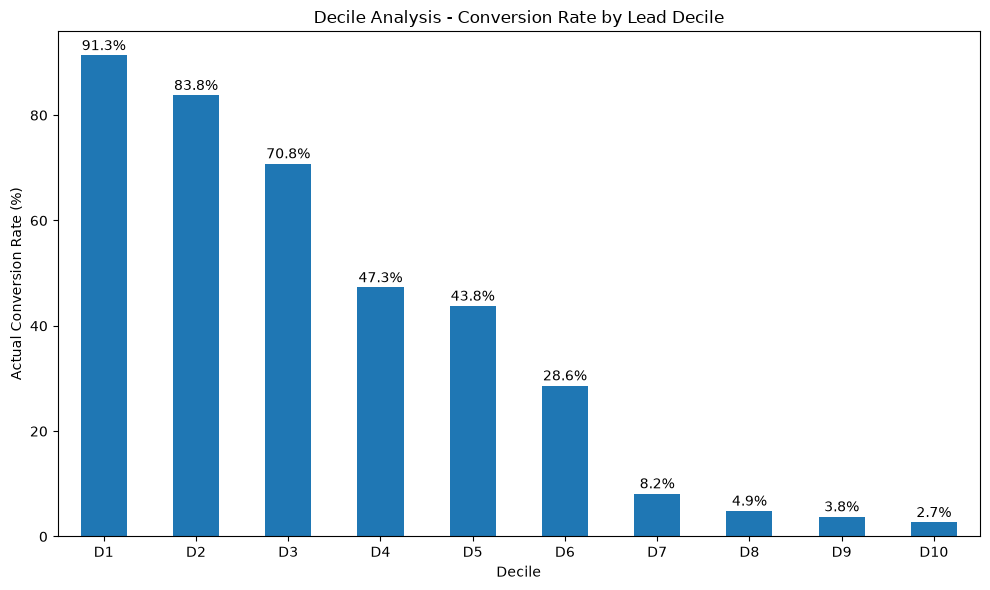

In [128]:
import matplotlib.pyplot as plt

plot_data = decile_summary.sort_values('Decile')

ax = plot_data.plot(
    x='Decile',
    y='Conversion_Rate',
    kind='bar',
    figsize=(10, 6),
    legend=False
)

plt.xlabel('Decile')
plt.ylabel('Actual Conversion Rate (%)')
plt.title('Decile Analysis - Conversion Rate by Lead Decile')
plt.xticks(rotation=0)

# Add conversion rate labels
for i, value in enumerate(plot_data['Conversion_Rate']):
    ax.text(
        i,
        value + 1,
        f'{value:.1f}%',
        ha='center'
    )

plt.tight_layout()
plt.show()

- Decile analysis was performed to validate whether the model effectively ranks leads according to their likelihood of conversion. The results show a strong decline in actual conversion rate from **91.35% in the highest-scored decile (D1)** to **2.70% in the lowest-scored decile (D10)**. This indicates that the model is effectively ranking higher-potential leads above lower-potential leads and can therefore support lead prioritization.


In [129]:
# Probabilities from the final model
y_test_prob = final_model.predict_proba(X_test_reduced)[:, 1]

# Test different thresholds
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

for threshold in [0.4, 0.5, 0.6, 0.7, 0.8]:
    y_pred_threshold = (y_test_prob >= threshold).astype(int)
    
    print(f"\nThreshold: {threshold}")
    print("Accuracy :", round(accuracy_score(y_test, y_pred_threshold), 3))
    print("Precision:", round(precision_score(y_test, y_pred_threshold), 3))
    print("Recall   :", round(recall_score(y_test, y_pred_threshold), 3))
    print("F1 Score :", round(f1_score(y_test, y_pred_threshold), 3))
    print("ROC AUC  :", round(roc_auc_score(y_test, y_test_prob), 3))
    


Threshold: 0.4
Accuracy : 0.806
Precision: 0.731
Recall   : 0.785
F1 Score : 0.757
ROC AUC  : 0.887

Threshold: 0.5
Accuracy : 0.8
Precision: 0.763
Recall   : 0.698
F1 Score : 0.729
ROC AUC  : 0.887

Threshold: 0.6
Accuracy : 0.805
Precision: 0.808
Recall   : 0.649
F1 Score : 0.72
ROC AUC  : 0.887

Threshold: 0.7
Accuracy : 0.787
Precision: 0.835
Recall   : 0.556
F1 Score : 0.668
ROC AUC  : 0.887

Threshold: 0.8
Accuracy : 0.767
Precision: 0.877
Recall   : 0.461
F1 Score : 0.604
ROC AUC  : 0.887


In [130]:
from sklearn.metrics import roc_auc_score

# Calculate ROC-AUC score
roc_auc = roc_auc_score(y_test, y_test_prob)

print("Test ROC-AUC:", roc_auc)

Test ROC-AUC: 0.8867292589808513


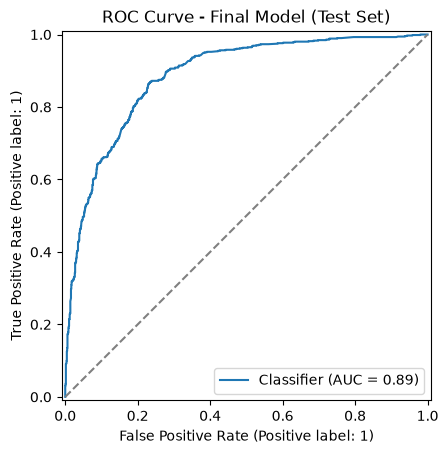

In [131]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(y_test, y_test_prob)
plt.title("ROC Curve - Final Model (Test Set)")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")  # chance line
plt.show()

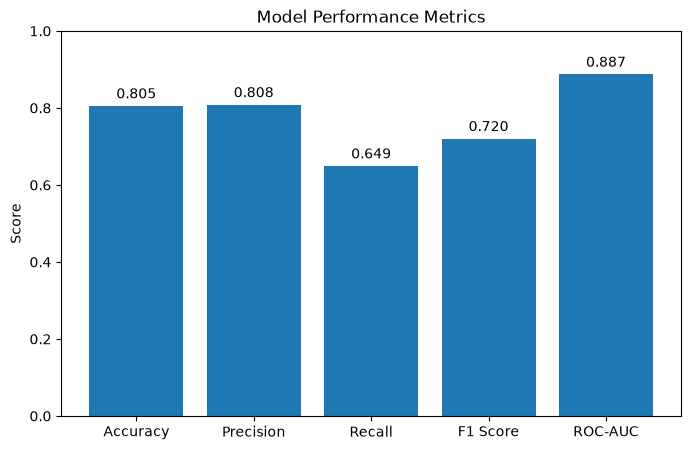

In [132]:
import matplotlib.pyplot as plt

metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC']
values = [0.805, 0.808, 0.649, 0.720, 0.887]

plt.figure(figsize=(8, 5))

bars = plt.bar(metrics, values)

plt.title('Model Performance Metrics')
plt.ylabel('Score')
plt.ylim(0, 1)

# Display values on top of bars
for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.02,
        f'{value:.3f}',
        ha='center'
    )

plt.show()

In [133]:
thresholds = [0.50, 0.60, 0.70, 0.75, 0.80, 0.85, 0.90]

results = []

for threshold in thresholds:
    selected = y_test_prob >= threshold
    
    conversion_rate = y_test[selected].mean() * 100
    selection_rate = selected.mean() * 100
    number_selected = selected.sum()
    
    results.append([
        threshold,
        number_selected,
        selection_rate,
        conversion_rate
    ])

business_results = pd.DataFrame(
    results,
    columns=[
        "Probability Threshold",
        "Selected Leads",
        "Selection Rate (%)",
        "Conversion Rate (%)"
    ]
)

business_results

,Probability Threshold,Selected Leads,Selection Rate (%),Conversion Rate (%)
0,0.50,651,35.227273,76.344086
1,0.60,572,30.952381,80.769231
2,0.70,474,25.649351,83.544304
3,0.75,430,23.268398,85.581395
4,0.80,374,20.238095,87.700535
5,0.85,319,17.261905,88.714734
6,0.90,251,13.582251,90.836653


##### Threshold Selection

- The default classification threshold of 0.50 resulted in a higher recall but an observed conversion rate of 76.34% among the selected leads. Since the business requirement is to identify a group of leads with at least 80% actual conversion, the threshold was increased to 0.60.

In [134]:
# Apply the business threshold
threshold = 0.60

y_test_pred = (y_test_prob >= threshold).astype(int)

In [135]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Training probabilities
y_train_prob = final_model.predict_proba(X_train_reduced)[:, 1]

# Apply the same business threshold
threshold = 0.60
y_train_pred = (y_train_prob >= threshold).astype(int)

print("Training Metrics at Threshold 0.60")
print("Accuracy:", accuracy_score(y_train, y_train_pred))
print("Precision:", precision_score(y_train, y_train_pred))
print("Recall:", recall_score(y_train, y_train_pred))
print("F1 Score:", f1_score(y_train, y_train_pred))

print("Testing Metrics at Threshold 0.60")
print("Accuracy:", accuracy_score(y_test, y_test_pred))
print("Precision:", precision_score(y_test, y_test_pred))
print("Recall:", recall_score(y_test, y_test_pred))
print("F1 Score:", f1_score(y_test, y_test_pred))

Training Metrics at Threshold 0.60
Accuracy: 0.8285984848484849
Precision: 0.8524955436720143
Recall: 0.6714636714636715
F1 Score: 0.7512271745533085
Testing Metrics at Threshold 0.60
Accuracy: 0.8051948051948052
Precision: 0.8076923076923077
Recall: 0.648876404494382
F1 Score: 0.719626168224299


In [136]:
from sklearn.metrics import confusion_matrix

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

print("Training Confusion Matrix:")
print(confusion_matrix(y_train, y_train_pred))

Confusion Matrix:
[[1026  110]
 [ 250  462]]
Training Confusion Matrix:
[[4212  331]
 [ 936 1913]]


- At a threshold of 0.60, the selected leads achieved an observed conversion rate of 80.77%, while approximately 30.95% of the leads were selected. This comes with a reduction in recall to approximately 64.8%, representing a trade-off between identifying more potential converters and prioritizing leads with a higher likelihood of conversion.

- Therefore, a threshold of 0.60 was adopted for business lead prioritization.

##### Lead Scoring

The final model generates a conversion probability for each lead. To make these predictions easier for the business team to understand and use for lead prioritization, the probabilities are converted into a **0–100 Lead Score**.

A higher Lead Score indicates a higher predicted likelihood of conversion. The Lead Score can therefore be used to rank leads and help the sales team focus their efforts on higher-potential leads.

Based on the selected business threshold of **0.60**, leads with a **Lead Score of 60 or above** are considered high-potential leads for prioritization.


In [137]:
# Convert probability into a 0-100 lead score
lead_score = y_test_prob * 100

# Create lead scoring dataframe
lead_score_df = pd.DataFrame({
    "Conversion Probability": y_test_prob,
    "Lead Score": lead_score
})

lead_score_df.head()

,Conversion Probability,Lead Score
0,0.334748,33.474835
1,0.735953,73.595261
2,0.489961,48.996124
3,0.167459,16.745930
4,0.098425,9.842517


In [138]:
lead_score_df = lead_score_df.sort_values(
    by="Lead Score",
    ascending=False
).reset_index(drop=True)

lead_score_df.head(10)

,Conversion Probability,Lead Score
0,0.999676,99.967630
1,0.999135,99.913521
2,0.998736,99.873564
3,0.998736,99.873564
4,0.998736,99.873564
5,0.998736,99.873564
6,0.998736,99.873564
7,0.998648,99.864793
8,0.998632,99.863156
9,0.998599,99.859910


In [139]:
lead_score_df["Lead Category"] = pd.cut(
    lead_score_df["Lead Score"],
    bins=[0, 40, 60, 80, 100],
    labels=["Low", "Medium", "High", "Very High"],
    include_lowest=True
)

In [140]:
lead_score_df["Lead Category"].value_counts().sort_index()

Lead Category
Low          1083
Medium        193
High          198
Very High     374
Name: count, dtype: int64

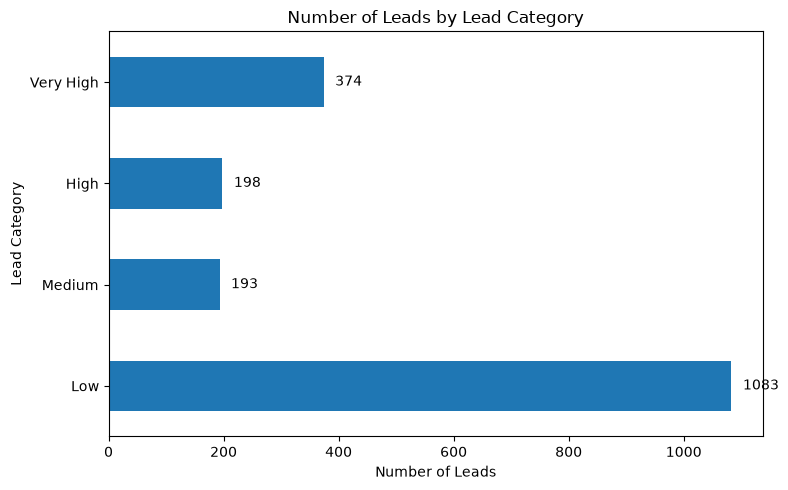

In [141]:
import matplotlib.pyplot as plt

lead_category_counts = (
    lead_score_df["Lead Category"]
    .value_counts()
    .sort_index()
)

ax = lead_category_counts.plot(
    kind="barh",
    figsize=(8, 5)
)

plt.xlabel("Number of Leads")
plt.ylabel("Lead Category")
plt.title("Number of Leads by Lead Category")

# Add count labels
for i, value in enumerate(lead_category_counts):
    ax.text(value + 20, i, str(value), va="center")

plt.tight_layout()
plt.show()

##### Lead Score Category Interpretation

The predicted conversion probabilities were converted into a 0–100 Lead Score and divided into four categories: Low (0–40), Medium (40–60), High (60–80), and Very High (80–100).

Out of 1,848 test leads, **572 leads (30.95%)** received a Lead Score of 60 or above. These leads were identified as the high-potential group based on the selected business threshold of 0.60 and can be prioritized by the sales team.

The remaining leads can be handled according to their Lead Score, allowing the business to prioritize sales efforts toward leads with higher predicted conversion likelihood.


## Business Recommendations

* During the two-month internship period, X Education should prioritize **recall** to identify as many potential converting leads as possible. A classification threshold of **0.4** can be used.

* When the quarterly target has already been achieved, X Education should prioritize **precision** to reduce unnecessary calls. A higher classification threshold of **0.8** can be used.

* The lead scoring model can help the sales team prioritize leads and use their time more efficiently by focusing on leads with a higher likelihood of conversion.


## Conclusion

The lead scoring model was developed to help X Education identify leads that are more likely to convert. The model performed well on the test data and can help the sales team prioritize leads more effectively.

The analysis also showed that the classification threshold should depend on the company's business objective. During the two-month internship period, a lower threshold of **0.4** can be used to prioritize **recall** and identify more potential customers. When the quarterly target has already been achieved, a higher threshold of **0.8** can be used to prioritize **precision** and reduce unnecessary calls.

Overall, the model can support X Education in making its lead-contacting process more targeted and efficient.
